# Fitness Landscape Cómo Potencial de Selección Natural

En este cuaderno estudiaré, centrandose en un potencial de fitness a través de fitness landscape,fenómenos de selección sexual y su interacción con la selección natural. Consideraré dos fenotipos o estrategias, A y B. El fenotipo A tendrá mayor atractivo sexual y, por tanto, mayor éxito de apareamiento, mientras que el fenotipo B tendrá menor atractivo sexual pero también menor vulnerabilidad a los depredadores. Se va a trabajar a 3 niveles de profundización para abordar el primero. La primera sería un ftiness  constante e independiente de la frecuencia del fenotipo si se agregará algún parámetro lineal realizado con la saturación sexual. Luego, será un fitness dependiente de la frecuencia del fitness sin el parámetro adicional de 


Para cada nivel de profundización, se realizará un análisis de la matriz de pagos dónde se verán los casos de equilibrio luego se estudiará la ecuación del replicador, se realizará el proceso de Moran dónde se podrá hacer la comparativa con la ecuación del replicador debido a la estocasticidad. Luego, se realizarán 3 gráficas relacionadas con el fitness drift, el fitness promedio y la diferencia de fitness para cada población inicial de A y densidad de depredadores. Luego, se deberá construir un filtro para ver el comportamiento de las superficies. 


Aún está en proceso este cuaderno,
última fecha de edición : 16-nov-2026.

---


## Librerías
Necesario cargarlas para que el código funcione de forma correcta. 


In [10]:

# Standard library
import os, csv, time, random, inspect, importlib
from datetime import datetime
from pathlib import Path
from itertools import product
from functools import lru_cache

# Numerical analysis
import numpy as np
import pandas as pd
import scipy.stats as stats
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, minimize_scalar, differential_evolution, least_squares
from scipy.ndimage import gaussian_filter

# Visualization
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from IPython.display import Image as IPyImage, HTML, IFrame, display,Image

---

### Modulo de importación de gráficas

Con el fin de ser consistentes en términos de gráficas, tipografía tamaños y no ocupar espacio en este cuaderno se utilizó un modulo externo tipo Python que puede ser ubicado en /inputs/graphs. 



In [11]:
import Inputs.graphs as ia

## Construcción computacional del modelo evolutivo

El modelo se construye en tres niveles de complejidad: (1) matriz de pagos constante, (2) pagos dependientes de la frecuencia fenotípica, y (3) extensión con mecanismos ecológicos y reproductivos no lineales. Los tres niveles comparten la misma estructura computacional, de modo que las funciones de análisis de equilibrios, ecuación del replicador, proceso de Moran y superficies evolutivas se reutilizan sin cambios.

1. **Sistema y parámetros.** Parámetros de selección sexual y depredación. 
2. **Matrices de pagos.** Definición general. 
3. **Fitness esperado.** Fitness de cada fenotipo, su diferencia y el promedio poblacional.
4. **Equilibrios.** Importación de modulos que me analizan los equilibrios dependiendo de las entradas de la matriz de pago.
5. **Ecuación del replicador.** Solución numérica de la dinámica determinista para distintas condiciones iniciales y parámetros.
6. **Cadena de Markov y ecuación maestra.**
   - **Matriz de transición** (`matriz_transicion`): cadena de nacimiento-muerte sobre los N+1 estados (p = i/N) con estados absorbentes en p = 0 y p = 1. Las probabilidades de subir, bajar o permanecer usan los fitness π_A y π_B ponderados por las fracciones de cada fenotipo en la población.
   - **Ecuación maestra** (`analizar_ecuacion_maestra`): itera x ← x·M durante `n_pasos` y registra distribuciones, probabilidad acumulada de fijación de A y B, supervivencia en estados transitorios, media y varianza de p. El tiempo medio exacto de absorción y la probabilidad eventual de fijación se obtienen resolviendo el sistema lineal (I − Q)⁻¹ sobre la submatriz de estados transitorios.
   - **Tiempo de convergencia** (`tiempo_convergencia`): número de pasos necesarios para que la masa de probabilidad en estados interiores caiga por debajo de `tol`.
   - **Visualización** (`graficarEcuacionMaestra`): curvas de probabilidad acumulada de fijación de A y B en función del paso de la cadena, con parámetros anotados en el título.
7. **Proceso de Moran.** Modelo estocástico de población finita con probabilidades de reproducción basadas en el fitness.
7. **Mutaciones.** Mecanismos de mutación y su efecto frente al caso sin mutación.
9. **Superficies evolutivas.** Diferencia de fitness, fitness promedio y estimadores de deriva para distintas composiciones y niveles de depredación.

Este esquema permite evaluar sistemáticamente cómo cada mecanismo biológico adicional modifica la dinámica evolutiva, tanto determinista como estocástica.

---

### Definiciones Biológicas



### DEF parámetros de Selección y Depredación

Parámetros basados en literatura y deducciones propias acordes únicamente en la población de los Guppies.

In [12]:
# Reproducción y Muerte
# Valores NO arbitrarios sacados de [4] y [7]
s_a = 0.86; s_b = 0.53; d_a = 0.107; d_b = 0.023 

# Primer cálculo (S_a y S_b)
calc_s = ((1 + s_a) / (1 + s_b) - 1) * 100
print(f"Cuando ignoramos efectos no lineales, excluyendo depredación, vemos que la diferencia de fitness será: {calc_s:.2f}%")

# Segundo cálculo (D_a y D_b)
calc_d = ((1 + d_a) / (1 + d_b) - 1) * 100
print(f"Cuando ignoramos efectos no lineales, excluyendo apareamiento, vemos que la diferencia de fitness será: {calc_d:.2f}%")

Cuando ignoramos efectos no lineales, excluyendo depredación, vemos que la diferencia de fitness será: 21.57%
Cuando ignoramos efectos no lineales, excluyendo apareamiento, vemos que la diferencia de fitness será: 8.21%


---
## Matriz de Pagos

Primero necesitamos construir una matriz de pagos en general que nos servirá para la parte de la ecuación del replicador y para ver las dinámicas de estabilidad dado los parámetros de los pagos. Las condiciones de estabilidad varia dependiendo del modelo, por lo que, el código para esto será descrita en cada sección. Aun que si podemos escribir un punto interior generalizado.

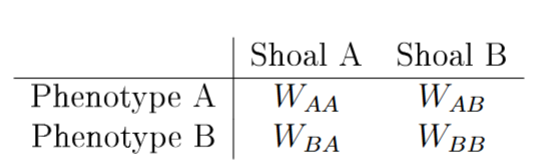

In [13]:
display(Image(filename='Inputs/Payoffs Matrix.png'))

### Condiciones de Estabilidad 

Cómo dependiendo de las entradas se decidió agregar dos módulos de código que me permita construir las condiciones de estabilidad de forma amplia sin tener que saturar el actual cuaderno. Se importan a continuación las funciones a utilizar.

In [14]:
from Inputs.stability_linear import (
    evaluar,               # Evalúa una función de pago pasándole solo los argumentos que su firma acepta.
    payoff,                # Devuelve la tupla (a, b, c, d) de la matriz 2x2 evaluando WAA, WAB, WBA, WBB con los parámetros dados.
    pEstable,              # Calcula el equilibrio interior p* = (d-b)/(a-b-c+d); devuelve None si cae fuera de (0, 1).
    classification,        # Clasifica el régimen del juego (A domina B, B domina A, Biestabilidad, Coexistencia estable, Neutralidad) y reporta p* y las ESS.
    findParameters,        # Busca por optimización (DE + LS) parámetros que realicen cada uno de los cinco regímenes clásicos y devuelve una tabla con un ejemplo por régimen.
    barridoParametros,     # Recorre un producto cartesiano de parámetros y clasifica cada combinación; opcionalmente escribe el resultado a CSV.
)


from Inputs.stability_nonlinear import (
    deltaPi,                      # Evalúa Δπ(p) = p·(a−c) + (1−p)·(b−d), la diferencia de fitness que impulsa al replicador.
    classificationNoLineal,       # Clasifica el flujo del replicador en 0 ≤ p ≤ 1 buscando raíces y tangencias; devuelve régimen, estabilidad de p=0 y p=1, equilibrios interiores y atractores.
    findParametersNoLineal,       # Busca parámetros que realicen cada uno de los seis regímenes no lineales (incluye multi-equilibrio) y valida el resultado con classificationNoLineal.
    barridoParametrosNoLineal,    # Barrido cartesiano de parámetros que clasifica cada combinación con classificationNoLineal; opcionalmente escribe el resultado a CSV.
)

### Eq replicador

De forma general podemos  construir la ecuación del replicador que depende explícitamente de las entradas de la matriz de pagos. 

In [15]:
def piA(p, WAA, WAB, **kwargs):
    par = {**kwargs, 'p': float(p)}
    return p*evaluar(WAA, **par) + (1-p)*evaluar(WAB, **par)

def piB(p, WBA, WBB, **kwargs):
    par = {**kwargs, 'p': float(p)}
    return p*evaluar(WBA, **par) + (1-p)*evaluar(WBB, **par)

def eqReplicador(p, WAA, WAB, WBA, WBB, **kwargs):
    return p*(1-p)*(
        piA(p, WAA, WAB, **kwargs)
        - piB(p, WBA, WBB, **kwargs)
    )

---
## Markov Chains 

Este pedazo es para que dadas las ecuaciones de transición encontremos la matriz de transición talque podamso encontrar el número de pasos que necesitamos para encontrar la fijación de alguna especie o para llegar a un punto estable. 

In [16]:

def matriz_transicion(N, **kwargs):

    if not isinstance(N, (int, np.integer)) or N < 2:
        raise ValueError("N must be an integer >= 2.")

    WAA, WAB, WBA, WBB = (
        kwargs[k] for k in ('WAA', 'WAB', 'WBA', 'WBB')
    )

    parametros = {
        k: v for k, v in kwargs.items()
        if k not in ('WAA', 'WAB', 'WBA', 'WBB')
    }

    T = np.zeros((N+1, N+1))
    T[0, 0] = T[N, N] = 1.0

    for i in range(1, N):
        p = i/N

        fA = piA(p, WAA, WAB, **parametros)
        fB = piB(p, WBA, WBB, **parametros)
        denominador = i*fA + (N-i)*fB

        if not (np.isfinite(fA) and np.isfinite(fB)
                and fA > 0 and fB > 0):
            raise ValueError("Expected fitness must be positive and finite.")

        T_mas = (i*fA/denominador)*((N-i)/N)
        T_menos = ((N-i)*fB/denominador)*(i/N)

        T[i, i+1] = T_mas
        T[i, i-1] = T_menos
        T[i, i] = 1-T_mas-T_menos

    return T


In [17]:
def tiempo_convergencia(M, x0, tol=1e-8, max_steps=100000):

    x = np.asarray(x0, dtype=float).copy()

    for T in range(max_steps + 1):

        # Probabilidad que permanece en estados interiores
        prob_transitoria = np.sum(x[1:-1])

        if prob_transitoria < tol:
            return T, x

        x = x @ M

    return None, x

## Ecuación Maestra

Para ver la probabilidad acumulada

In [18]:
def analizar_ecuacion_maestra(M, x0, n_pasos=20000):

    N = M.shape[0] - 1
    x = np.asarray(x0, dtype=float).copy()

    # Frecuencias posibles de A
    frecuencias = np.arange(N + 1) / N

    # Distribuciones a lo largo de la evolución
    distribuciones = [x.copy()]

    for n in range(n_pasos):
        x = x @ M
        distribuciones.append(x.copy())

    distribuciones = np.array(distribuciones)

    # Probabilidad de fijación acumulada en cada paso
    prob_A = distribuciones[:, -1]
    prob_B = distribuciones[:, 0]

    # Probabilidad de continuar en estados transitorios
    supervivencia = distribuciones[:, 1:-1].sum(axis=1)

    # Proporción promedio de A
    media = distribuciones @ frecuencias

    # Varianza de la proporción de A
    varianza = (
        distribuciones @ (frecuencias**2) - media**2
    )

    # Submatriz de estados transitorios
    Q = M[1:-1, 1:-1]
    I = np.eye(N - 1)

    # Tiempo medio exacto de absorción por estado
    tiempos = np.linalg.solve(
        I - Q,
        np.ones(N - 1)
    )

    tiempo_medio = x0[1:-1] @ tiempos

    # Probabilidad eventual de fijación de A
    fijacion_A = np.zeros(N + 1)
    fijacion_A[-1] = 1.0

    fijacion_A[1:-1] = np.linalg.solve(
        I - Q,
        M[1:-1, -1]
    )

    prob_fijacion_A = x0 @ fijacion_A
    prob_fijacion_B = 1 - prob_fijacion_A

    return {
        "distribuciones": distribuciones,
        "prob_A": prob_A,
        "prob_B": prob_B,
        "supervivencia": supervivencia,
        "media": media,
        "varianza": varianza,
        "tiempo_medio": tiempo_medio,
        "fijacion_A": prob_fijacion_A,
        "fijacion_B": prob_fijacion_B
    }


---
### DEF de Mutaciones 
Definimos **N** como la población, **p** como la proporción inicial de individuos de tipo A, siendo los de A los que tienen una elección sexualmás fuerte y B los menos favorecidos por esta selección.

In [19]:
# Números de mutaciones [9,10]
muPrima, L = (5.97)*10**(-9), 118000
u = muPrima * L 
mu = 1/u
print(f"El número de generaciones necesarios para mutaciones es de {round(1/(u))} generaciones")

El número de generaciones necesarios para mutaciones es de 1420 generaciones


In [20]:
def mutacionPeriodica(generacion, intervalo, population):
    """
    Aplica una mutación reversible cada `intervalo` generaciones.
    """
    if generacion % intervalo == 0:
        idx = np.random.randint(len(population))
        population[idx] = "B" if population[idx] == "A" else "A"
    return population

In [21]:
def mutacionPoisson(population):
    """
    Aplica mutaciones a la población.
    """

    lam = len(population) * 1/mu                      
    k = stats.poisson.rvs(lam)         # número real de mutaciones
    if k == 0:
            return population
        
    k = min(k, len(population))                   
    idxs = np.random.choice(len(population), size=k, replace=False)[0]

    if population[idxs] == "A":
        population[idxs] = "B"

    else:
        population[idxs] = "A"
    
    return population

---

### Proceso de Moran

#### DEF de Poblaciones
Definimos **N** como la población, **p** como la proporción inicial de individuos de tipo A, siendo los de A los que tienen una elección sexualmás fuerte y B los menos favorecidos por esta selección.

In [22]:
def populationDef(N,p):
    """
    Crea una población de tamaño N con una proporción inicial p de individuos de tipo A y (1-p) de tipo B.
    """
    if p == 0 : 
        population = ['B'] * (N-1) + ['A']
    elif p == 1 :
        population = ['A'] * (N-1) + ['B']
    else:
        population = ['A'] * int(p * N) + ['B'] * int((1 - p) * N)
    return population

In [23]:
def MPFitDinamico(N, p, T, g=0, poisson=False,
                  fit_a=None, fit_b=None, mu=mu, seed=None, **kwargs):

    if N < 2 or T < 1 or not 0 <= p <= 1:
        raise ValueError("Check N, T and initial frequency p.")

    rng = np.random.default_rng(seed)
    i = int(round(N*p))
    history = np.empty(T+1)
    history[0] = i/N

    funcA = piA if fit_a is None else fit_a
    funcB = piB if fit_b is None else fit_b

    def fitness(func, q):
        return float(func(q, **kwargs)) if callable(func) else float(func)

    for t in range(1, T+1):
        if 0 < i < N:
            q = i/N
            fA, fB = fitness(funcA, q), fitness(funcB, q)

            if not (np.isfinite(fA) and np.isfinite(fB) and fA > 0 and fB > 0):
                raise ValueError("Fitness must be positive and finite.")

            total = i*fA + (N-i)*fB
            plus = (i*fA/total)*(N-i)/N
            minus = ((N-i)*fB/total)*i/N

            u = rng.random()
            if u < plus:
                i += 1
            elif u < plus + minus:
                i -= 1

        # Optional reversible mutations
        if g > 1 and t % g == 0:
            i += -1 if rng.random() < i/N else 1
        elif poisson:
            for _ in range(rng.poisson(N*mu)):
                i += -1 if rng.random() < i/N else 1

        history[t] = i/N

    return history[-1], history, fitness(funcA, i/N), fitness(funcB, i/N)


In [24]:

def barridoHeat(modelo, pagos, Ns, p0s, etas, r0s=None, eta_c=None,
                T_heat=2000, R_heat=1, salto=5):

    W = dict(zip(('WAA', 'WAB', 'WBA', 'WBB'), pagos))
    opciones_r0 = [None] if r0s is None else r0s
    total = 0

    for n in Ns:
        for p_ini in p0s:
            for r_val in opciones_r0:
                par = {}
                nombre = f'Mod{modelo}_N{n}_p0{p_ini:.2f}'
                titulo = f'Moran heat map — Model {modelo} | N={n}, p₀={p_ini:.2f}'

                if r_val is not None:
                    par['r0'] = float(r_val)
                    nombre += f'_r0{r_val:.4f}'
                    titulo += f', r₀={r_val:.3f}'

                if eta_c is not None:
                    par['eta_c'] = float(eta_c)
                    nombre += f'_etac{eta_c:.3f}'
                    titulo += f', ηc={eta_c:.3f}'

                nombre += f'_T{T_heat}_R{R_heat}_E{len(etas)}'

                fig, ax = ia.plotHeat(
                    tamanio=(9, 6),
                    legendname='Mean frequency of phenotype A, $p$' if R_heat > 1
                               else 'Frequency of phenotype A, $p$',
                    tittle=titulo,
                    xlabel='Moran steps',
                    ylabel=r'Predation density, $\eta_d$',
                    save_name=f'{nombre}.png',
                    process_func=MPFitDinamico,
                    N=n, p0=p_ini, T=T_heat, R=R_heat, salto=salto,
                    etas=etas, g=0, poisson=False, seed=42,
                    mostrar=False, **W, **par
                )
                plt.close(fig)
                total += 1

    print(f'Model {modelo}: {total} heat maps saved in Outputs/HeatPlot/')


---

## Fitness Landscape

1. Definimos las funciones X,Y,Z para que puedan ser leíadas fácilmente por el plot que genera el fitness landscape. 

In [25]:
def DeltaW(x,y,func,n):
    X,Y = np.meshgrid(x,y)
    Z= np.zeros_like(X,dtype=float )
    for i in range(X.shape[0]):        
        for j in range(X.shape[1]):
            Z[i, j] = func(X[i, j], Y[i, j])[n]
    return X,Y,Z

2. Construir las 3 diferentes superficies.

In [26]:
def drift(p, eta_d, N=100, steps=100, R=30, seed=42, **kwargs):
    """Mean frequency change per Moran step over R realizations."""
    rng = np.random.default_rng(seed)
    pendientes, finales = [], []

    for _ in range(R):
        final, history, *_ = MPFitDinamico(
            N=N, p=p, T=steps, eta_d=eta_d,
            seed=int(rng.integers(0, 2**32-1)), **kwargs
        )
        pendientes.append((final - history[0])/steps)
        finales.append(final)

    pendientes = np.asarray(pendientes)
    error = pendientes.std(ddof=1)/np.sqrt(R) if R > 1 else 0.0
    return pendientes.mean(), error, np.mean(finales)


def piA_piB(p, eta_d, WAA, WAB, WBA, WBB, **kwargs):
    """Expected fitness of A, B, and their difference."""
    a = piA(p, WAA, WAB, eta_d=eta_d, **kwargs)
    b = piB(p, WBA, WBB, eta_d=eta_d, **kwargs)
    return a, b, a-b


def meanPi(p, eta_d, WAA, WAB, WBA, WBB, **kwargs):
    """Frequency-weighted mean population fitness."""
    a, b, _ = piA_piB(
        p, eta_d, WAA, WAB, WBA, WBB, **kwargs
    )
    return p*a+(1-p)*b, a, b

In [27]:
def graficarFitness(modelo, pagos, p, eta_d, **parametros):
    W = dict(zip(('WAA', 'WAB', 'WBA', 'WBB'), pagos))
    carpeta = Path('Outputs/FitnessLandscape')
    carpeta.mkdir(parents=True, exist_ok=True)

    sufijo = '_'.join(f'{k}{v:.3f}' for k, v in parametros.items())

    superficies = [
        ('difFit', piA_piB, 2, 'Fitness difference'),
        ('meanFit', meanPi, 0, 'Mean population fitness')
    ]

    for tipo, funcion, indice, etiqueta in superficies:
        f = lambda p0, eta: funcion(p0, eta, **W, **parametros)
        X, Y, Z = DeltaW(p, eta_d, f, indice)
        nombre = f'mod{modelo}_{tipo}' + (f'_{sufijo}' if sufijo else '')

        fig = ia.plotFL(
            (900, 650), etiqueta, f'{etiqueta} — Model {modelo}',
            'Phenotype A frequency, p', 'Predation density, ηd',
            nombre, X, Y, Z
        )

        fig.write_image(str(carpeta / f'{nombre}.png'), scale=2)


3. Filtro para que no se vea tan ruidoso la superficie. Seguramente sea un filtro gaussiano. 

In [28]:
def suavizarDrift(Z, sigma=1.0):
    """Gaussian smoothing of the stochastic drift landscape."""
    return gaussian_filter(Z, sigma=sigma, mode='reflect')

---
## Parámetros de Ejecución

In [29]:
# General parameters — Models 1, 2 and 3
N = [10, 100]
eta_d = np.linspace(0, 1, 10)
r0 = np.linspace(0, 0.25, 5)
p = np.linspace(0, 1, 10)

# Moran process and stochastic drift
T = 10000
steps = 5                 # Number of drift realizations (R)

# Model 3 — Nonlinear parameters
eta_c = 0.776
r0_fijo3 = 0.25
r0_vals = r0              # Same r0 sweep for all models

# Heat maps
N_heat = N.copy()
eta_heat = np.linspace(eta_d.min(), eta_d.max(), 25)
p0_heat = [0.2, 0.5, 0.8]
r0_heat = [0.05, 0.25]

T_heat = 2000
R_heat = 1
salto_heat = 5


---
### Modelo 1: Pagos lineales independientes de la frecuencia. 

1. Definición de las entradas para la matriz. 

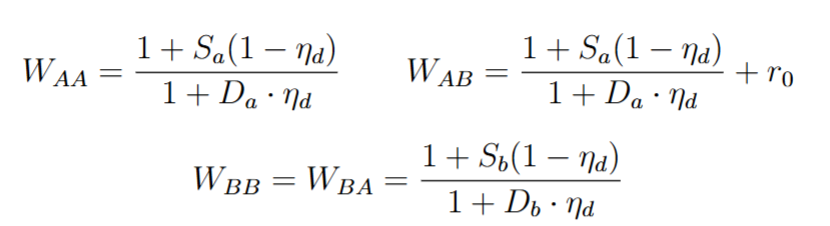

In [30]:
display(Image(filename='Inputs/Lineal.png'))

Sean Sa y Sb el éxito reproductivo relativo asociado a cada fenotipo; 
Da  y Db, la facilidad con que cada uno es detectado y devorado por el depredador; 
nd es un número con valor entre 0  a 1 que habla de la densidad de depredadores  ;
r0 será un parámetro lineal adicional que representa una ventaja sexual adicional del fenotipo A cuando su contexto es solo de B's.

In [31]:
def WAA_1(eta_d, sa=s_a, da=d_a):
    return (1+sa*(1-eta_d))/(1+eta_d*da)


def WAB_1(eta_d, r0, sa=s_a, da=d_a):
    return WAA_1(eta_d, sa=sa, da=da) + r0


def WBA_1(eta_d, sb=s_b, db=d_b):
    return (1+sb*(1-eta_d))/(1+eta_d*db)


def WBB_1(eta_d, sb=s_b, db=d_b):
    return WBA_1(eta_d, sb=sb, db=db)


2. Análisis de estabilidad, barrido de parámetros y gráfica que analiza régimenes.

In [32]:
rangos = {
    'eta_d': (0.01, 0.99),
    'r0': (0, 0.25)
}

ejemplos1 = findParameters(
    WAA_1, WAB_1, WBA_1, WBB_1, rangos
)

display(ejemplos1)


,target,found,eta_d,r0,regime,p_star,ESS
0,A dominates B,True,0.593052,8.263757e-02,A dominates B,NaN,A
1,B dominates A,True,0.937813,2.646476e-02,B dominates A,NaN,B
2,Bistability,False,0.781890,1.062299e-07,B dominates A,NaN,B
3,Stable coexistence,True,0.870670,2.449456e-01,Stable coexistence,0.873261,Mixed
4,Neutrality,True,0.781889,6.666662e-11,Neutrality,NaN,None


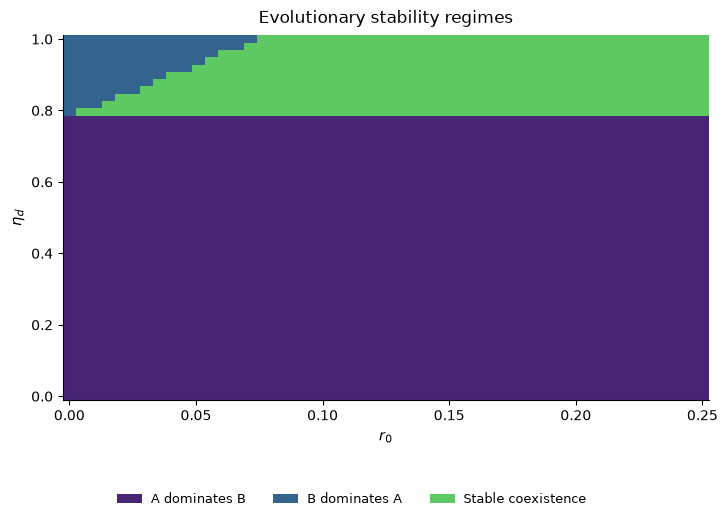

In [33]:
tabla1 = barridoParametros(
    WAA_1, WAB_1, WBA_1, WBB_1,
    barridos={
        'eta_d': np.linspace(0, 1, 50),
        'r0': np.linspace(0, 0.25, 50)
    },
    archivo='Outputs/EqReplicador/StabilityLineal.csv'
)

fig, ax = ia.mapaRegimenes(
    tabla1,
    nombre='StabilityModelo1'
)

3. Gráfica de replicador con parámetros elegidos

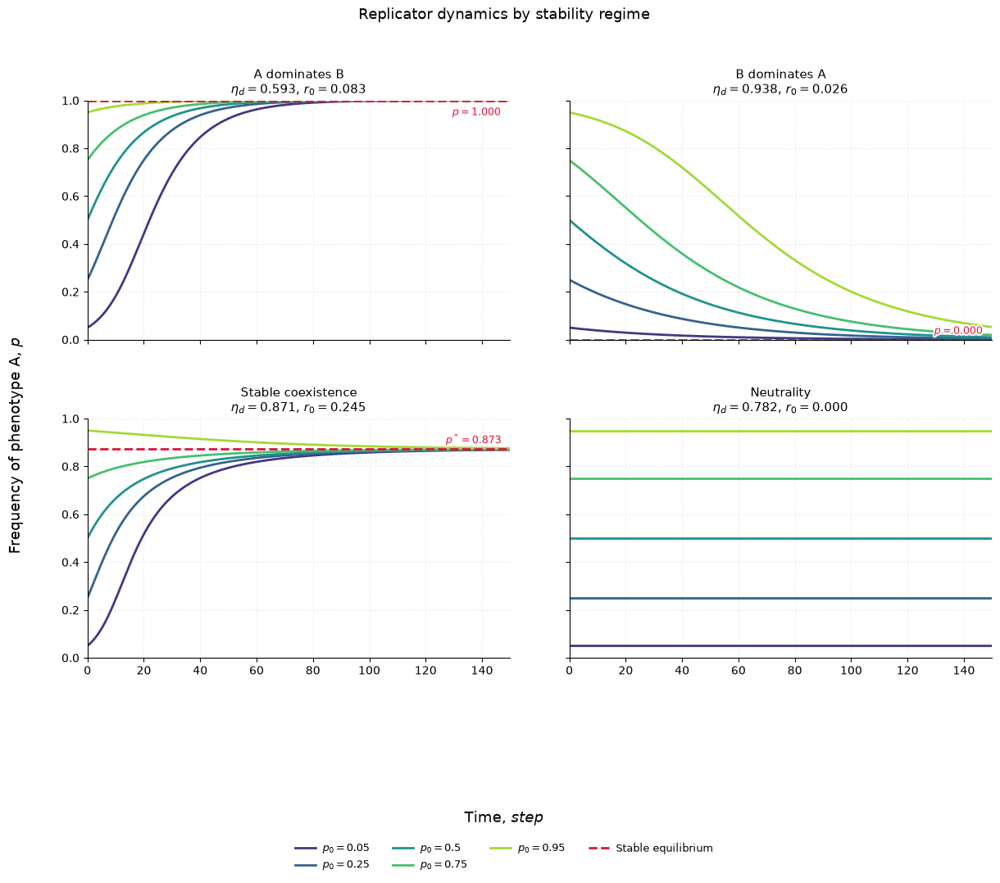

In [34]:
p0s = [0.05, 0.25, 0.5, 0.75, 0.95]

fig, axes = ia.plotRegimenesReplicador(
    ejemplos1, eqReplicador,
    WAA_1, WAB_1, WBA_1, WBB_1,
    pInicial=p0s,
    parametros=('eta_d', 'r0'),
    tFinal=150,
    nombre='regimenes_replicador'
)


4. Creación de Matriz de Markov

In [35]:
dicc1, convergencias1 = {}, {}

for n in N:
    inicio = datetime.now()
    x0 = np.zeros(n + 1)
    x0[n // 2] = 1
    combinaciones = 0

    for eta in eta_d:
        for r in r0:
            M1 = matriz_transicion(
                n, WAA=WAA_1, WAB=WAB_1, WBA=WBA_1, WBB=WBB_1,
                eta_d=float(eta), r0=float(r),
            )
            tconv, _ = tiempo_convergencia(M1, x0, tol=1e-6)
            resultados = analizar_ecuacion_maestra(M1, x0, n_pasos=15000)

            clave = (n, round(float(eta), 5), round(float(r), 5))
            dicc1[clave] = resultados
            convergencias1[clave] = tconv
            combinaciones += 1

    duracion = (datetime.now() - inicio).total_seconds()
    print(f"N={n} | {combinaciones} combinations | Execution: {duracion:.2f} s")

N=10 | 50 combinations | Execution: 1.24 s
N=100 | 50 combinations | Execution: 8.45 s


5. Grafica de ecuación Maestra basada en la matriz de transiciones

In [36]:
for (n, eta, r), resultados in dicc1.items():
    fig, ax = ia.graficarEcuacionMaestra(
        resultados, N=n, eta_d=eta, r0=r,
        guardar=f"Outputs/MasterEquation/Mod1_N{n}_eta{eta:.3f}_r0{r:.3f}.png",
        mostrar=False
    )
    plt.close(fig)

print(f"{len(dicc1)} plots saved in Outputs/MasterEquation/")

100 plots saved in Outputs/MasterEquation/


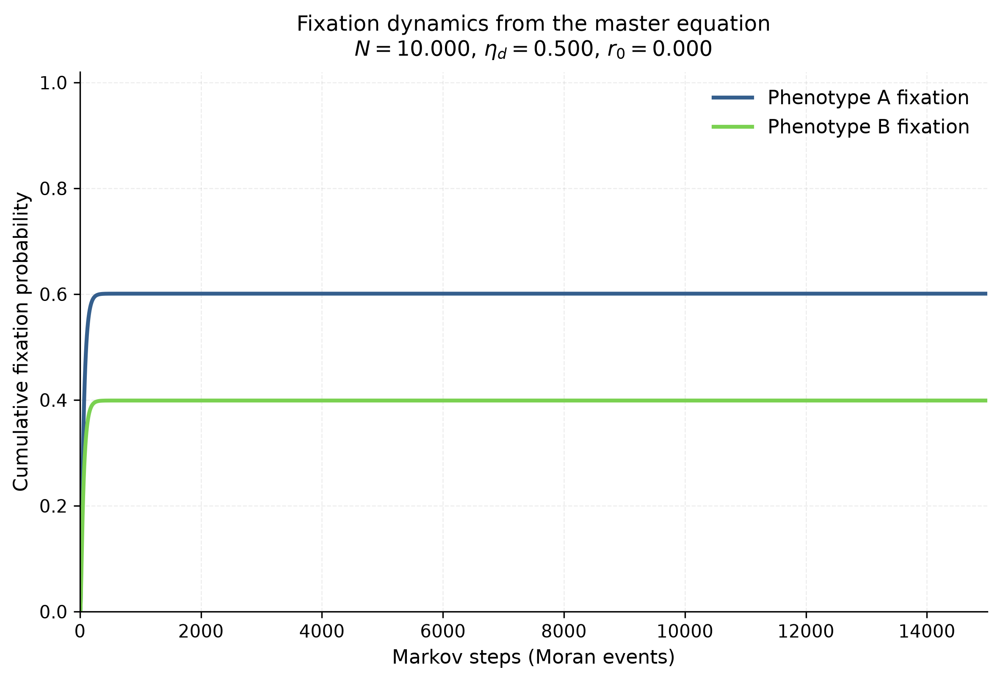

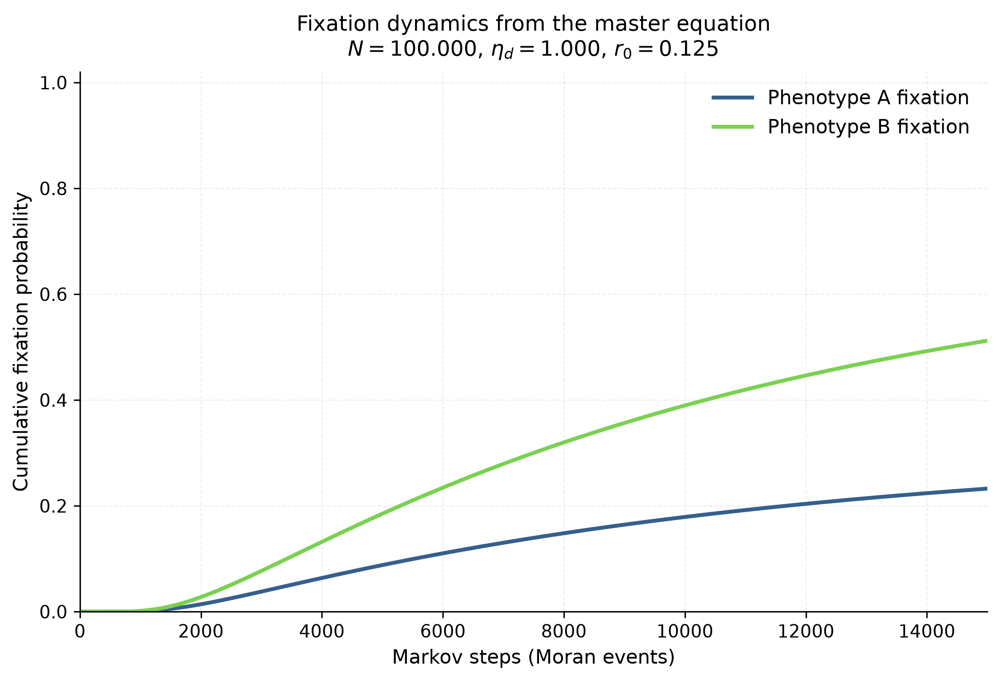

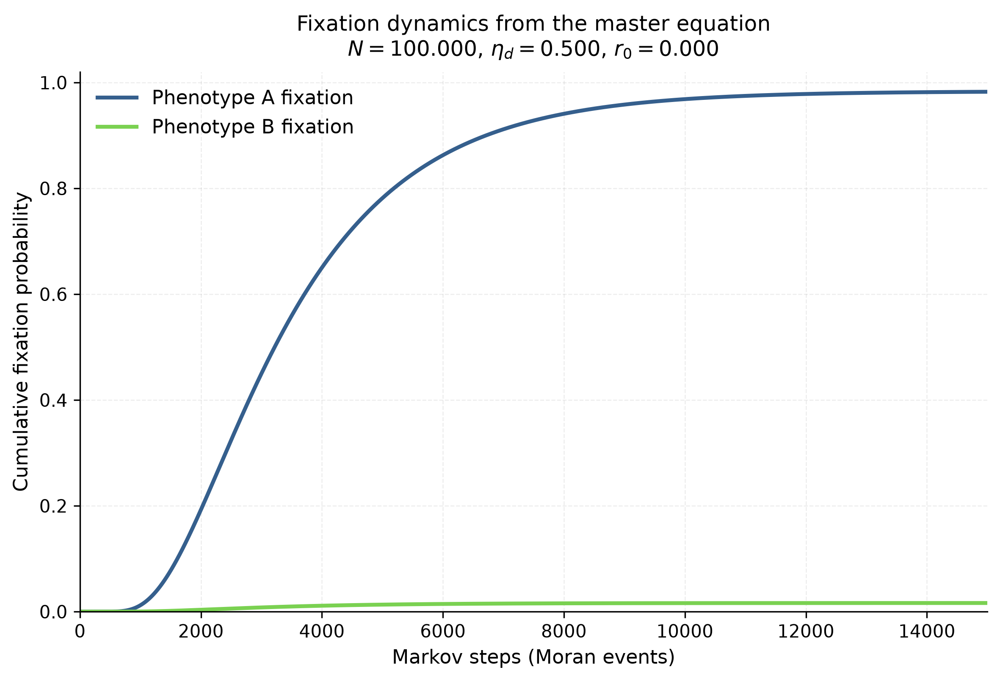

In [37]:
display(Image("Outputs/MasterEquation/Mod1_N10_eta0.500_r00.000.png"))
display(Image("Outputs/MasterEquation/Mod1_N100_eta1.000_r00.125.png"))
display(Image("Outputs/MasterEquation/Mod1_N100_eta0.500_r00.000.png"))

6. Grafica del Proceso de Moran

In [38]:
carpeta = Path('Outputs/MoranProcess')
carpeta.mkdir(parents=True, exist_ok=True)

for n in N:
    for eta in eta_d:
        for r in r0:
            par = {'eta_d': float(eta), 'r0': float(r)}
            res = classificationNoLineal(WAA_1, WAB_1, WBA_1, WBB_1, **par)

            fig, ax = ia.plot(
                tamanio=(9, 6), p=p,
                legendname='Initial frequency',
                tittle=f"{res['regime']} | N={n}, ηd={eta:.3f}, r₀={r:.3f}",
                xlabel='Moran steps',
                ylabel=r'Frequency of phenotype A, $p$',
                save_name=None, process_func=MPFitDinamico,
                N=n, T=T, g=0, poisson=False, seed=42,
                WAA=WAA_1, WAB=WAB_1, WBA=WBA_1, WBB=WBB_1,
                **par, mostrar=False
            )

            # Deterministic reference equilibria
            eq = list(res['equilibria'])
            eq += [{'p': q, 'stability': res[key]}
                   for q, key in [(0, 'p0'), (1, 'p1')]]

            for e in eq:
                if e['stability'] not in ('Stable', 'Unstable'): continue
                stable = e['stability'] == 'Stable'
                color = 'crimson' if stable else '#404040'
                ax.axhline(e['p'], color=color, ls='--' if stable else ':', lw=1.5)
                ax.annotate(fr"$p^*={e['p']:.3f}$",
                            (.98, e['p']), xycoords=('axes fraction', 'data'),
                            xytext=(-3, 6 if e['p'] < .95 else -12),
                            textcoords='offset points', ha='right', color=color)

            archivo = f'Mod1_N{n}_eta{eta:.3f}_r0{r:.3f}.png'
            fig.savefig(carpeta / archivo, dpi=300, bbox_inches='tight')
            plt.close(fig)

    print(f"N={n}: {len(eta_d)*len(r0)} plots saved.")

print(f"Total: {len(N)*len(eta_d)*len(r0)} plots in {carpeta}/")

N=10: 50 plots saved.
N=100: 50 plots saved.
Total: 100 plots in Outputs\MoranProcess/


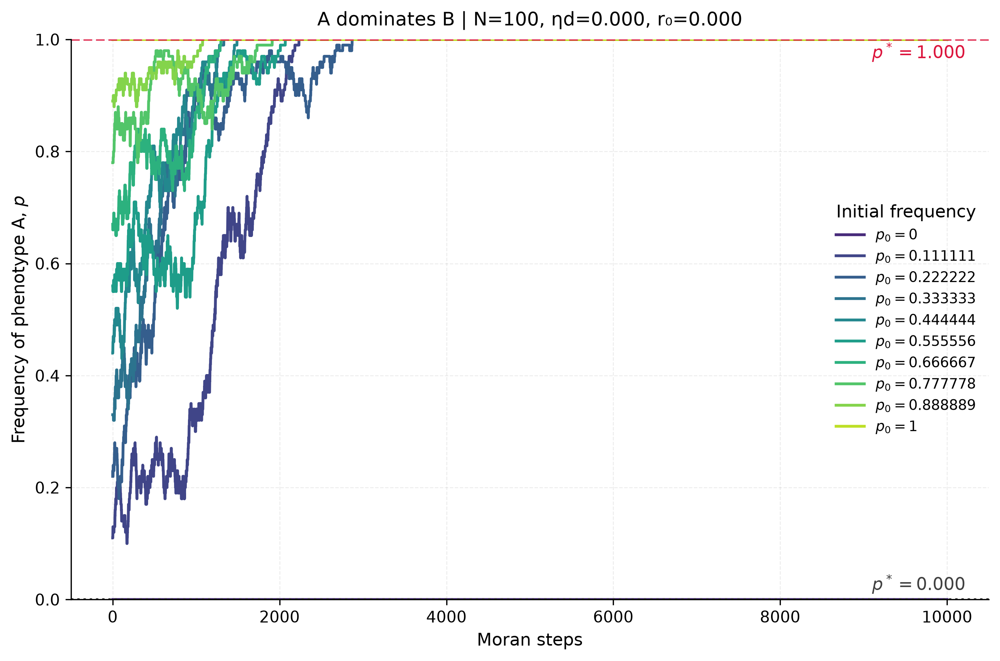

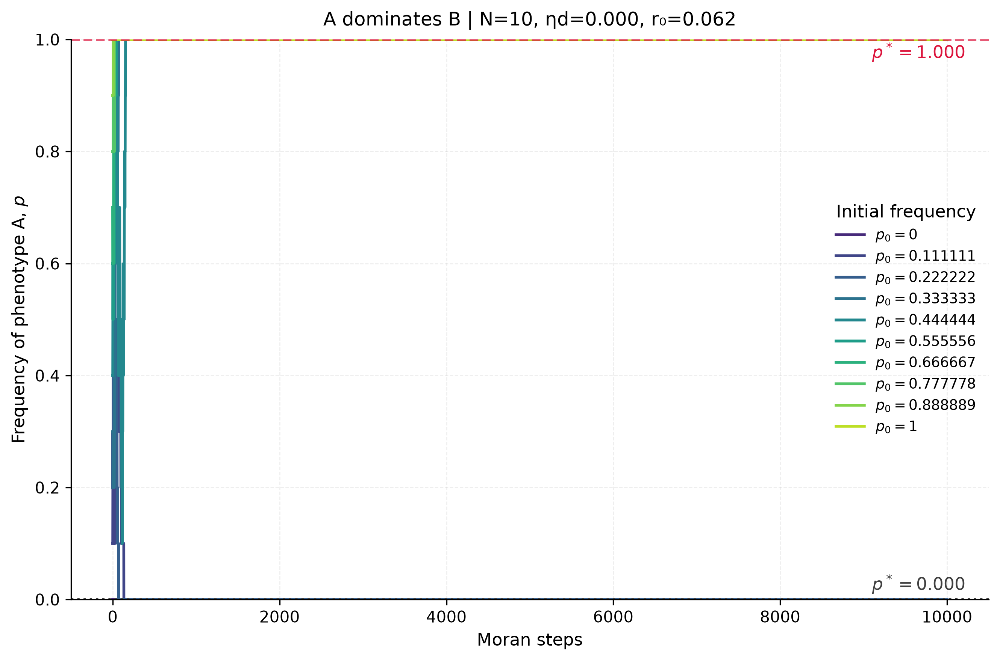

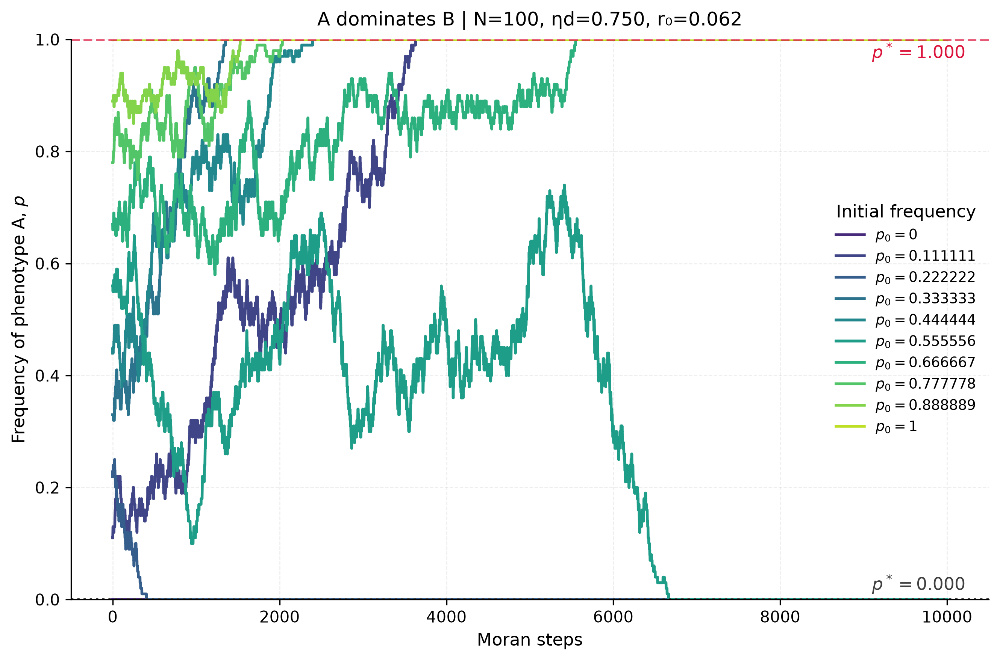

In [39]:
display(Image("Outputs/MoranProcess/Mod1_N100_eta0.000_r00.000.png"))
display(Image("Outputs/MoranProcess/Mod1_N10_eta0.000_r00.062.png"))
display(Image("Outputs/MoranProcess/Mod1_N100_eta0.750_r00.062.png"))

6.5. Mapas de Calor

In [40]:
barridoHeat(
    1, (WAA_1, WAB_1, WBA_1, WBB_1),
    Ns=N_heat, p0s=p0_heat, etas=eta_heat,
    r0s=r0_heat, T_heat=T_heat,
    R_heat=R_heat, salto=salto_heat
)

Model 1: 12 heat maps saved in Outputs/HeatPlot/


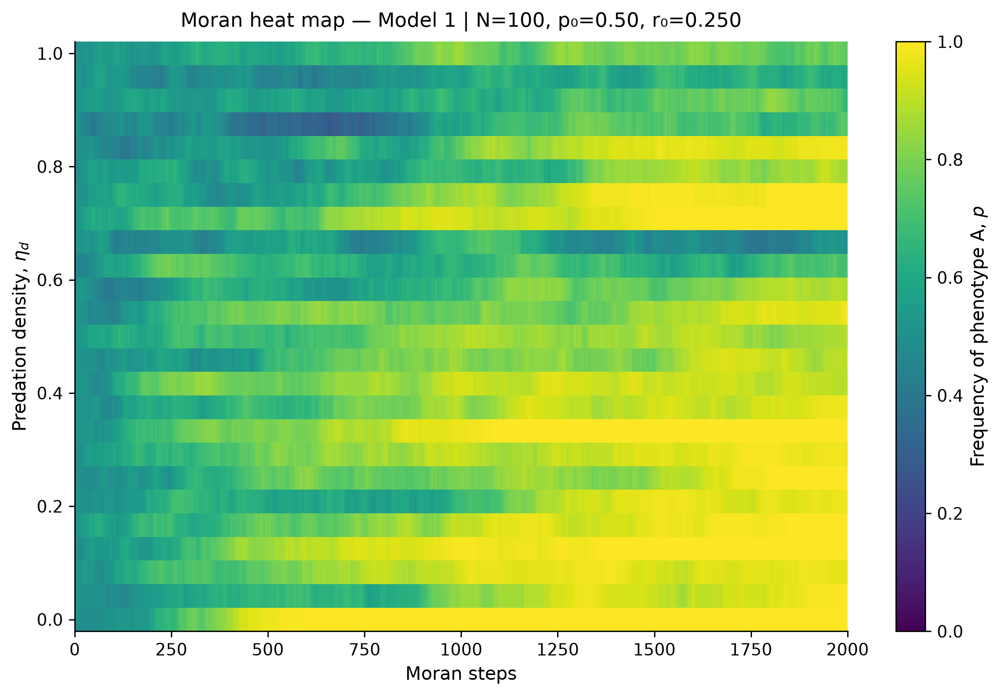

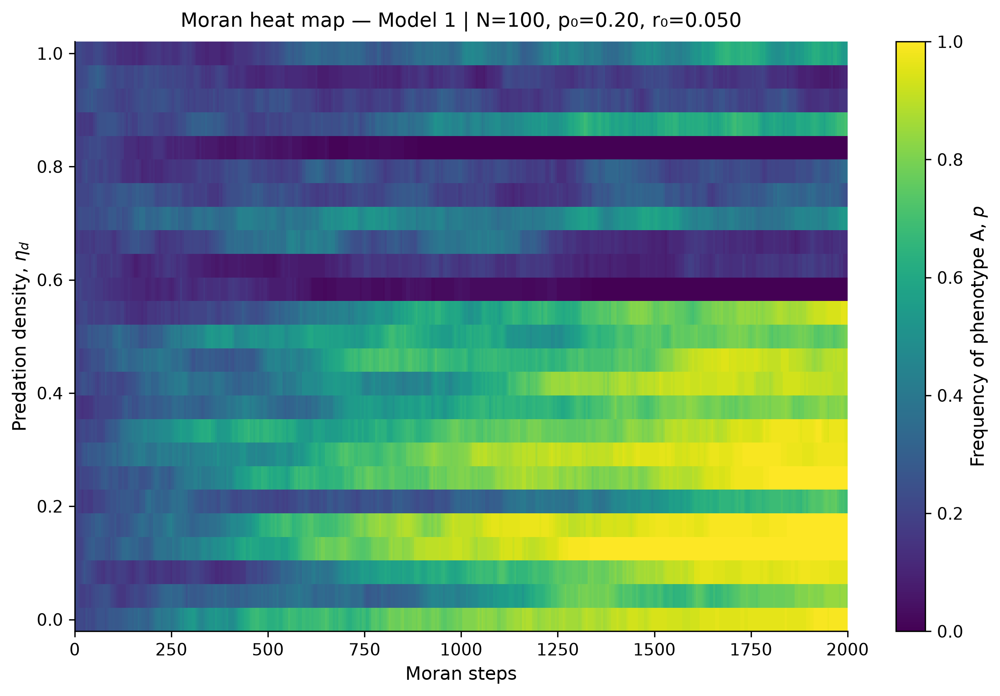

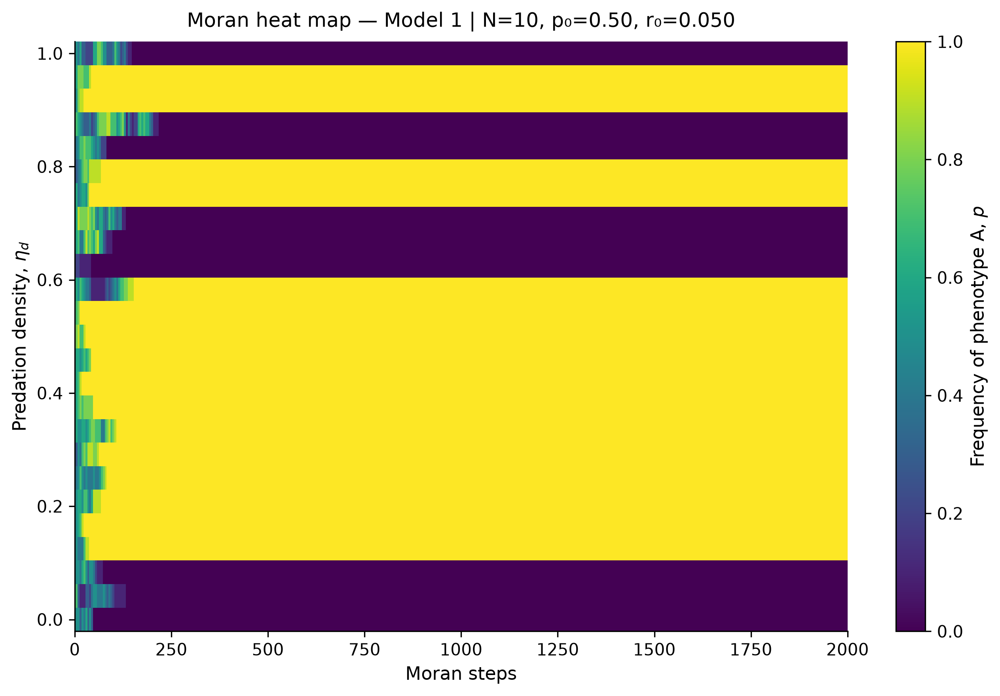

In [41]:
display(Image("Outputs/HeatPlot/Mod1_N100_p00.50_r00.2500_T2000_R1_E25.png"))
display(Image("Outputs/HeatPlot/Mod1_N100_p00.20_r00.0500_T2000_R1_E25.png"))
display(Image("Outputs/HeatPlot/Mod1_N10_p00.50_r00.0500_T2000_R1_E25.png"))

7. Fitness Landscape

In [42]:
for r in r0:
    graficarFitness(1, (WAA_1, WAB_1, WBA_1, WBB_1),
                   p, eta_d, r0=float(r))

In [43]:
landscapes1 = {}

for n in N:
    for r in r0:
        f = lambda p0, eta: drift(
            p0, eta, N=n, steps=T, R=steps,
            WAA=WAA_1, WAB=WAB_1, WBA=WBA_1, WBB=WBB_1,
            r0=float(r)
        )

        X, Y, Z = DeltaW(p, eta_d, f, 0)
        Zs = suavizarDrift(Z)

        # Preserve absorbing boundaries without mutation
        Zs[:, 0], Zs[:, -1] = Z[:, 0], Z[:, -1]
        landscapes1[(n, round(float(r), 5))] = (X, Y, Z, Zs)

        for filtro, valores in [('Raw', Z), ('Gaussian', Zs)]:
            ia.plotFL(
                tamanio=(950, 650),
                legendname='Mean drift per Moran step',
                tittle=f'{filtro} drift — Model 1 | N={n}, r₀={r:.3f}',
                xlabel='Initial frequency, p₀',
                ylabel='Predation density, ηd',
                save_name=f'Model1_N{n}_r0{r:.3f}_{filtro}',
                X=X, Y=Y, Z=valores
            )

        print(f"N={n}, r0={r:.3f} | Raw + Gaussian saved")

print(f"Total: {2*len(N)*len(r0)} HTML files.")

N=10, r0=0.000 | Raw + Gaussian saved
N=10, r0=0.062 | Raw + Gaussian saved
N=10, r0=0.125 | Raw + Gaussian saved
N=10, r0=0.188 | Raw + Gaussian saved
N=10, r0=0.250 | Raw + Gaussian saved
N=100, r0=0.000 | Raw + Gaussian saved
N=100, r0=0.062 | Raw + Gaussian saved
N=100, r0=0.125 | Raw + Gaussian saved
N=100, r0=0.188 | Raw + Gaussian saved
N=100, r0=0.250 | Raw + Gaussian saved
Total: 20 HTML files.


In [44]:
n, r, filtro = 10, 0.0625, 'Raw'

X, Y, Z, Zs = landscapes1[(n, round(r, 5))]

fig = ia.plotFL(
    tamanio=(950, 650),
    legendname='Mean drift per Moran step',
    tittle=f'{filtro} drift — Model 1 | N={n}, r₀={r:.4f}',
    xlabel='Initial frequency, p₀',
    ylabel='Predation density, ηd',
    save_name=None,
    X=X, Y=Y, Z=Z if filtro == 'Raw' else Zs
)

fig.show(renderer='notebook')


In [45]:
n, r, filtro = 10, 0.0625, 'Gaussian'

X, Y, Z, Zs = landscapes1[(n, round(r, 5))]

fig = ia.plotFL(
    tamanio=(950, 650),
    legendname='Mean drift per Moran step',
    tittle=f'{filtro} drift — Model 1 | N={n}, r₀={r:.4f}',
    xlabel='Initial frequency, p₀',
    ylabel='Predation density, ηd',
    save_name=None,
    X=X, Y=Y, Z=Z if filtro == 'Raw' else Zs
)

fig.show(renderer='notebook')


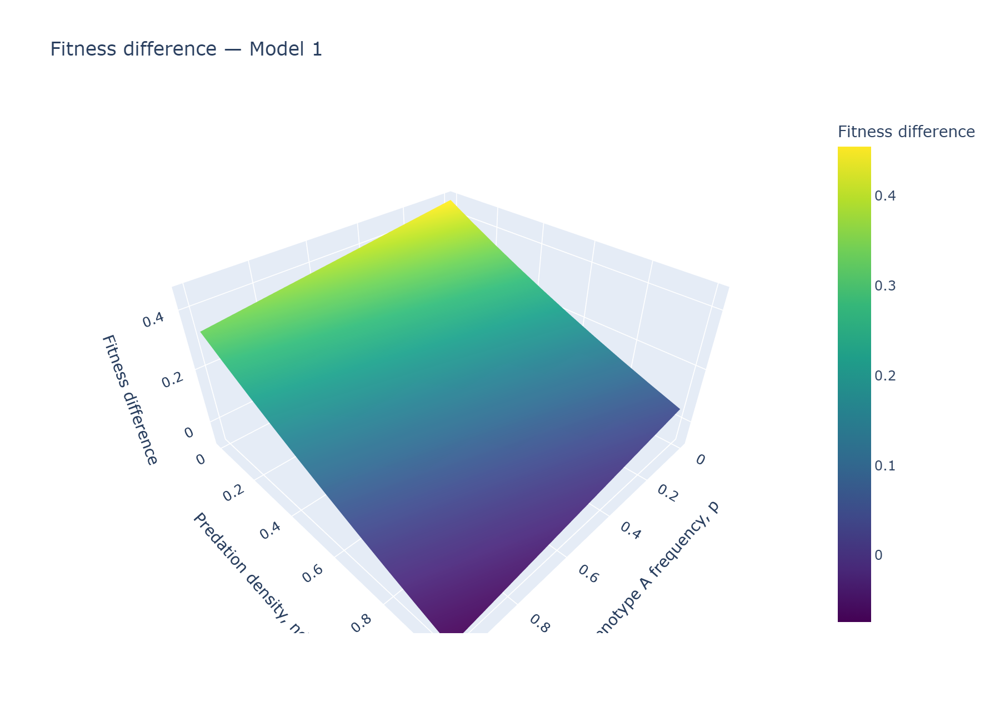

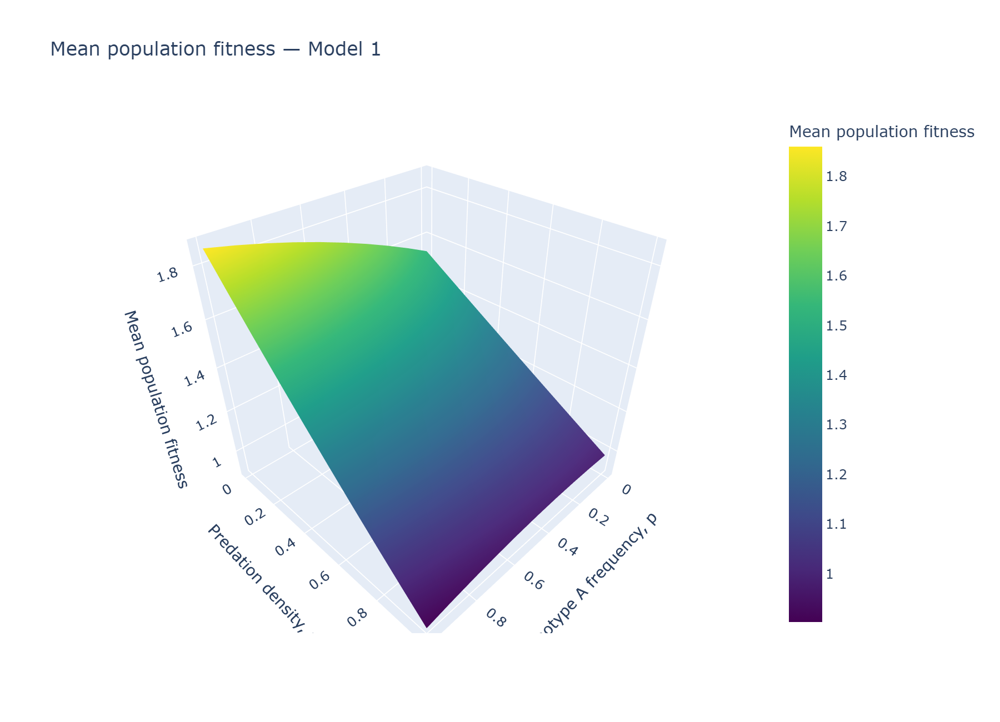

In [46]:
carpeta = Path('Outputs/FitnessLandscape')
r = 0.125

for tipo in ['difFit', 'meanFit']:
    archivo = carpeta / f'mod1_{tipo}_r0{r:.3f}.png'

    if archivo.exists():
        display(IPyImage(filename=str(archivo)))
    else:
        print(f'File not found: {archivo}')


---
### Modelo 2: Pagos dependientes de la frecuencia. 

1. Definición de las entradas para la matriz. 

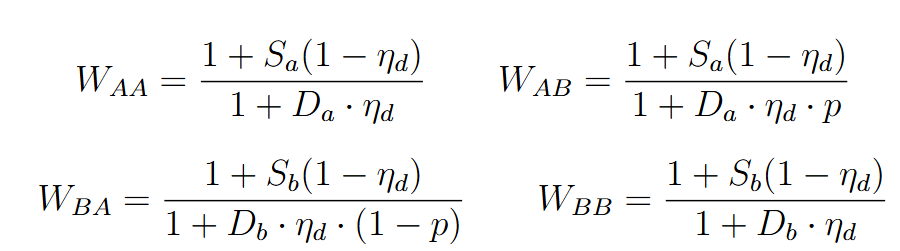

In [47]:
display(Image(filename='Inputs/FreqDepends.png'))

Dónde p será la densidad de individuos tipo A que hay en la población.

In [48]:

def WAA_2(eta_d, sa=s_a, da=d_a):
    return (1+sa*(1-eta_d))/(1+eta_d*da)


def WAB_2(p, eta_d, sa=s_a, da=d_a):
    return (1+sa*(1-eta_d))/(1+eta_d*da*p)


def WBA_2(p, eta_d, sb=s_b, db=d_b):
    return (1+sb*(1-eta_d))/(1+eta_d*db*(1-p))


def WBB_2(eta_d, sb=s_b, db=d_b):
    return (1+sb*(1-eta_d))/(1+eta_d*db)


2. Análisis de estabilidad, barrido de parámetros y gráfica que analiza régimenes.

In [49]:
# Parameter search
ejemplos2 = findParametersNoLineal(
    WAA_2, WAB_2, WBA_2, WBB_2,
    rangos={
        'eta_d': (0, 1)
    }
)

display(ejemplos2)

,target,found,eta_d,regime,p0,p1,p_star,equilibria,n_equilibria,attractors
0,A dominates B,True,0.466308,A dominates B,Unstable,Stable,NaN,[],0,p=1
1,B dominates A,False,1.000000,Stable coexistence,Unstable,Unstable,0.116751,"[{'p': 0.11675065014865643, 'stability': 'Stab...",1,p=0.116751
2,Stable coexistence,True,0.786161,Stable coexistence,Unstable,Unstable,0.659754,"[{'p': 0.6597537532999207, 'stability': 'Stabl...",1,p=0.659754
3,Bistability,False,0.874360,Stable coexistence,Unstable,Unstable,0.379104,"[{'p': 0.3791036486075366, 'stability': 'Stabl...",1,p=0.379104
4,Neutrality,False,0.846344,Stable coexistence,Unstable,Unstable,0.454435,"[{'p': 0.4544346055811514, 'stability': 'Stabl...",1,p=0.454435
5,Multiple equilibria,False,0.749451,Stable coexistence,Unstable,Unstable,0.845055,"[{'p': 0.8450552473861752, 'stability': 'Stabl...",1,p=0.845055


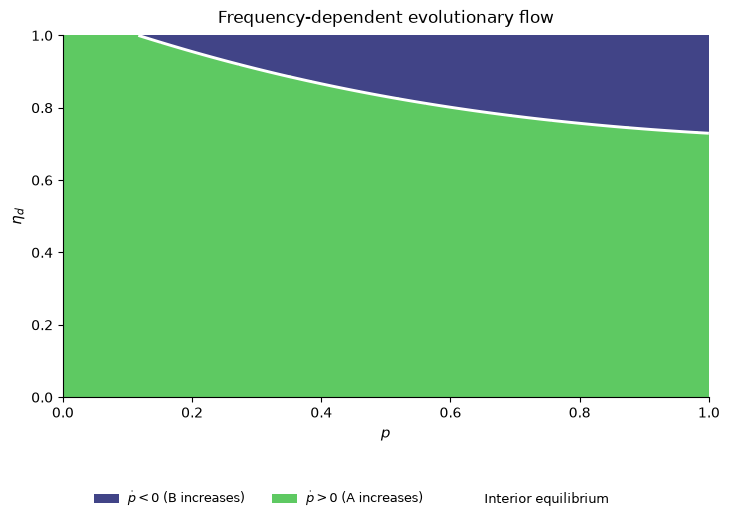

In [50]:
# Stability classification
tabla2 = barridoParametrosNoLineal(
    WAA_2, WAB_2, WBA_2, WBB_2,
    barridos={
        'eta_d': np.linspace(0, 1, 150)
    },
    archivo='Outputs/StabilityModelo2.csv'
)

# Evolutionary flow map
fig, ax = ia.mapaFlujoNoLineal(
    WAA_2, WAB_2, WBA_2, WBB_2,
    eta_d=np.linspace(0, 1, 150),
    p=np.linspace(0, 1, 150),
    nombre='StabilityModelo2'
)

3. Gráfica de replicador con parámetros elegidos

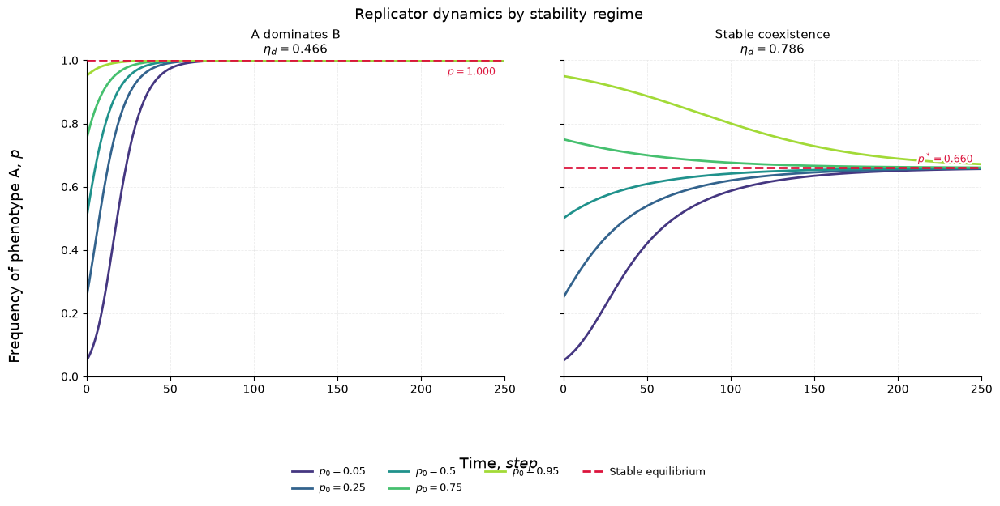

In [51]:
p0s = [0.05, 0.25, 0.5, 0.75, 0.95]

fig, axes = ia.plotRegimenesReplicador(
    ejemplos2, eqReplicador,
    WAA_2, WAB_2, WBA_2, WBB_2,
    pInicial=p0s,
    parametros=('eta_d',),
    tFinal=250,
    nombre='regimenes_replicador_modelo2'
)

4. Creación de Matriz de Markov

In [52]:
dicc2, convergencias2 = {}, {}

for n in N:
    inicio = datetime.now()
    x0 = np.zeros(n+1)
    x0[n//2] = 1

    for eta in eta_d:
        M2 = matriz_transicion(
            n, WAA=WAA_2, WAB=WAB_2, WBA=WBA_2, WBB=WBB_2,
            eta_d=float(eta)
        )

        tconv2, _ = tiempo_convergencia(M2, x0, tol=1e-6)
        resultados2 = analizar_ecuacion_maestra(M2, x0, n_pasos=15000)

        clave = (n, round(float(eta), 5))
        dicc2[clave] = resultados2
        convergencias2[clave] = tconv2

    duracion = (datetime.now()-inicio).total_seconds()
    print(f"N={n} | {len(eta_d)} combinations | Execution: {duracion:.2f} s")

N=10 | 10 combinations | Execution: 0.32 s
N=100 | 10 combinations | Execution: 2.02 s


5. Grafica de ecuación Maestra basada en la matriz de transiciones

In [53]:
for (n, eta), resultados in dicc2.items():
    fig, ax = ia.graficarEcuacionMaestra(
        resultados, N=n, eta_d=eta,
        guardar=f"Outputs/MasterEquation/Mod2_N{n}_eta{eta:.3f}.png",
        mostrar=False
    )
    plt.close(fig)

print(f"{len(dicc2)} plots saved.")

20 plots saved.


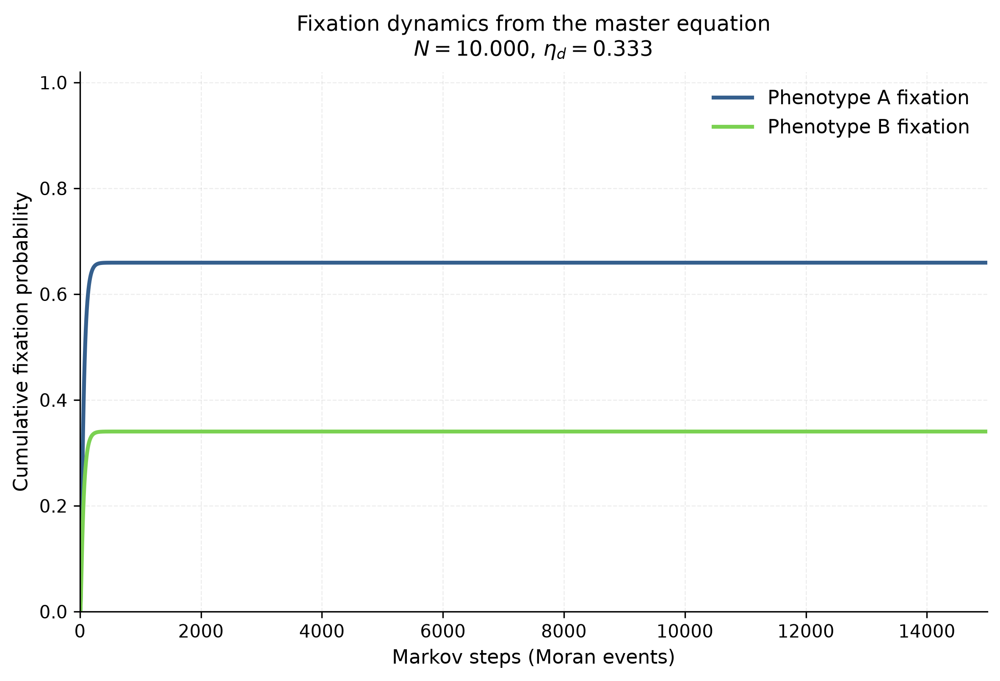

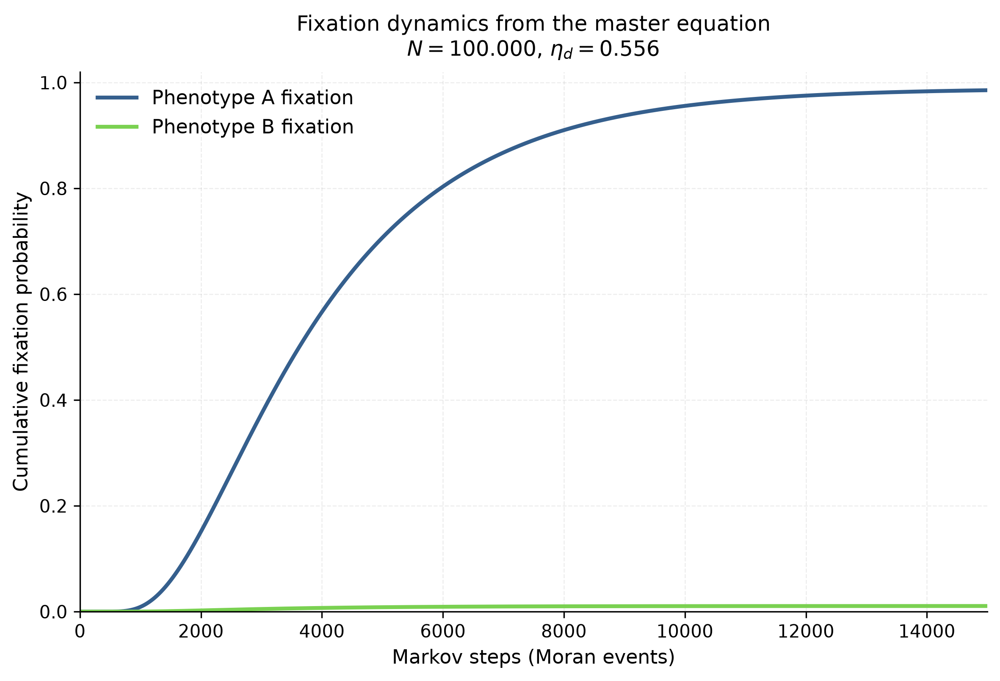

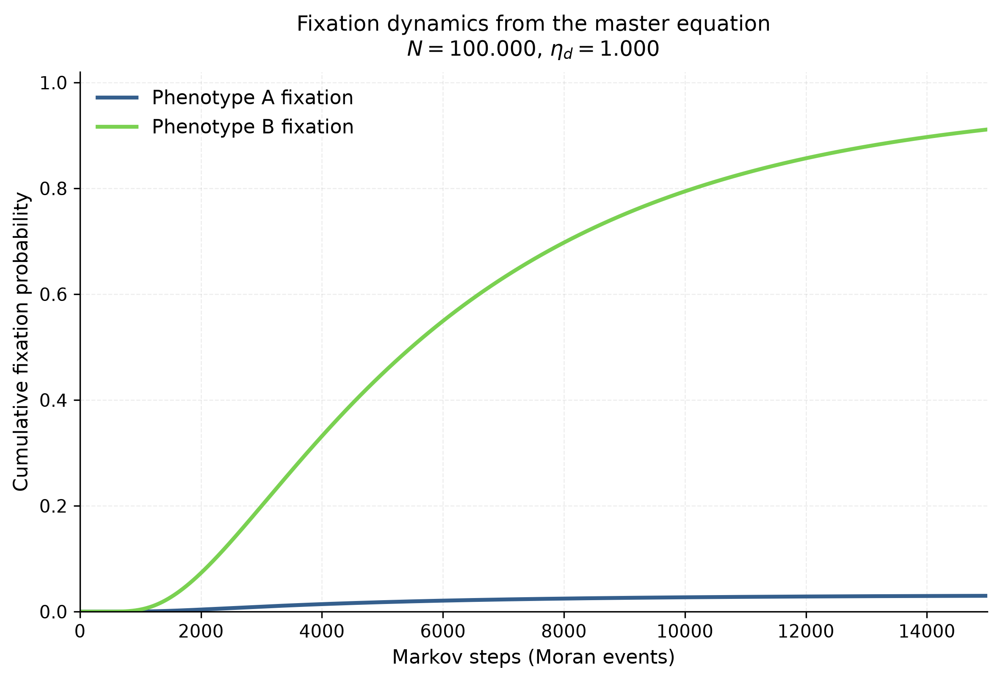

In [54]:
display(Image("Outputs/MasterEquation/Mod2_N10_eta0.333.png"))
display(Image("Outputs/MasterEquation/Mod2_N100_eta0.556.png"))
display(Image("Outputs/MasterEquation/Mod2_N100_eta1.000.png"))


6. Grafica del Proceso de Moran

In [55]:
carpeta = Path('Outputs/MoranProcess')
carpeta.mkdir(parents=True, exist_ok=True)

for n in N:
    for eta in eta_d:
        par = {'eta_d': float(eta)}
        res = classificationNoLineal(WAA_2, WAB_2, WBA_2, WBB_2, **par)

        fig, ax = ia.plot(
            tamanio=(9, 6), p=p,
            legendname='Initial frequency',
            tittle=f"{res['regime']} | N={n}, ηd={eta:.3f}",
            xlabel='Moran steps',
            ylabel=r'Frequency of phenotype A, $p$',
            save_name=None, process_func=MPFitDinamico,
            N=n, T=T, g=0, poisson=False, seed=42,
            WAA=WAA_2, WAB=WAB_2, WBA=WBA_2, WBB=WBB_2,
            **par, mostrar=False
        )

        # Deterministic reference equilibria
        eq = list(res['equilibria'])
        eq += [{'p': q, 'stability': res[key]}
               for q, key in [(0, 'p0'), (1, 'p1')]]

        for e in eq:
            if e['stability'] not in ('Stable', 'Unstable'): continue
            stable = e['stability'] == 'Stable'
            color = 'crimson' if stable else '#404040'
            ax.axhline(e['p'], color=color, ls='--' if stable else ':', lw=1.5)
            ax.annotate(fr"$p^*={e['p']:.3f}$",
                        (.98, e['p']), xycoords=('axes fraction', 'data'),
                        xytext=(-3, 6 if e['p'] < .95 else -12),
                        textcoords='offset points', ha='right', color=color)

        archivo = f'Mod2_N{n}_eta{eta:.3f}.png'
        fig.savefig(carpeta / archivo, dpi=300, bbox_inches='tight')
        plt.close(fig)

    print(f"N={n}: {len(eta_d)} plots saved.")

print(f"Total: {len(N)*len(eta_d)} plots in {carpeta}/")

N=10: 10 plots saved.
N=100: 10 plots saved.
Total: 20 plots in Outputs\MoranProcess/


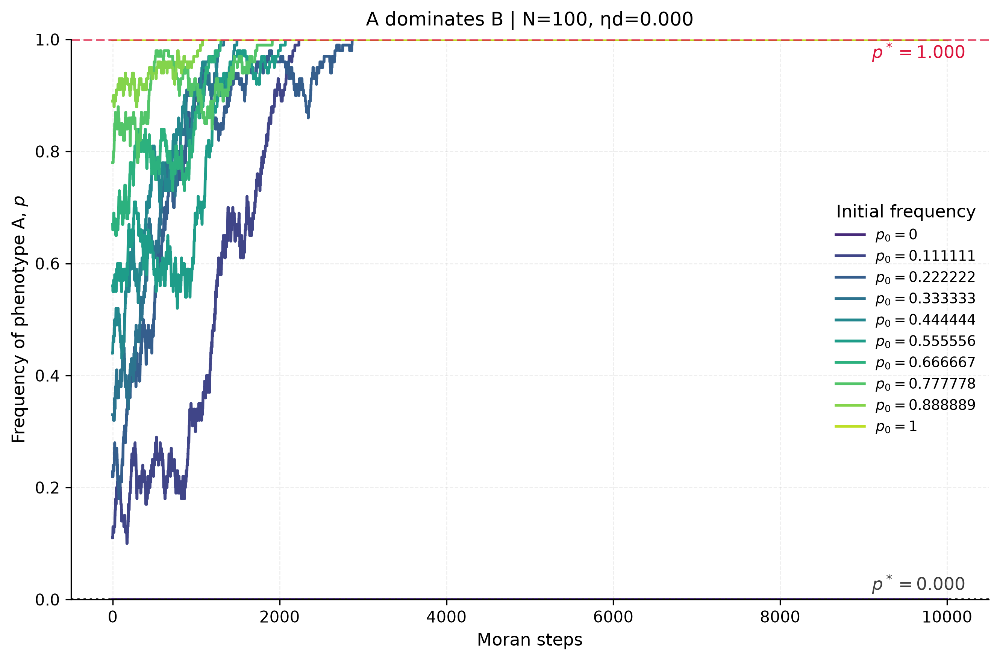

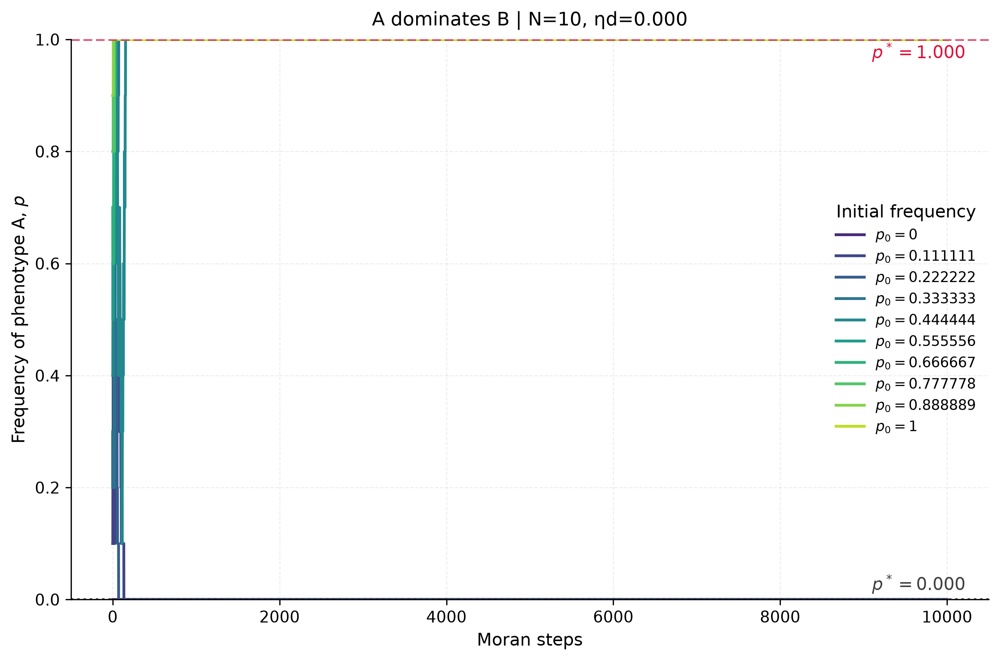

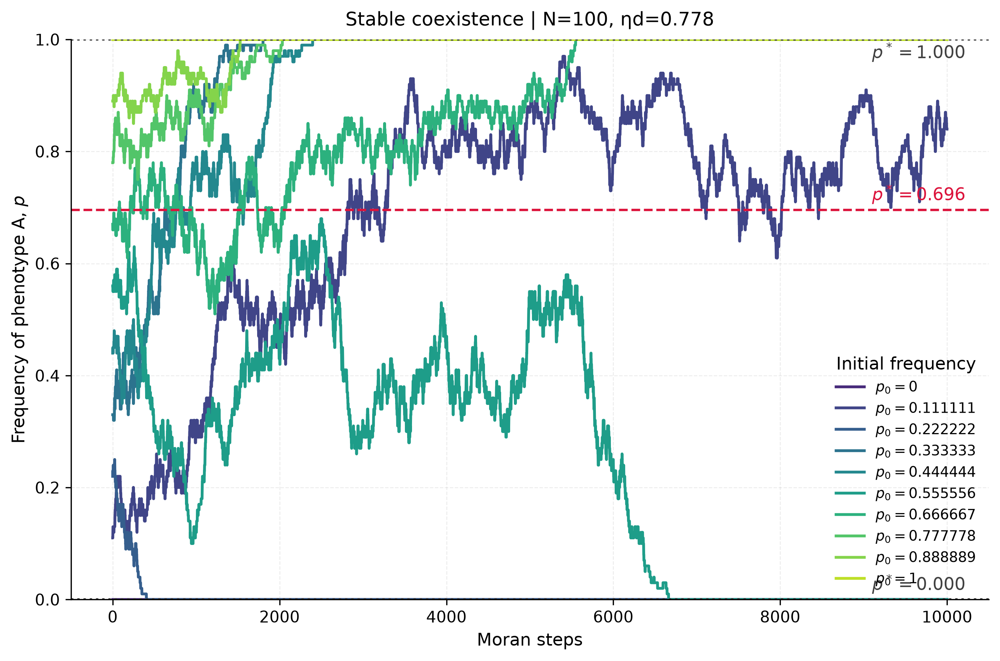

In [56]:
display(IPyImage(filename="Outputs/MoranProcess/Mod2_N100_eta0.000.png"))
display(IPyImage(filename="Outputs/MoranProcess/Mod2_N10_eta0.000.png"))
display(IPyImage(filename="Outputs/MoranProcess/Mod2_N100_eta0.778.png"))


6.5. Mapa de Calor

In [57]:
barridoHeat(
    2, (WAA_2, WAB_2, WBA_2, WBB_2),
    Ns=N_heat, p0s=p0_heat, etas=eta_heat,
    T_heat=T_heat, R_heat=R_heat, salto=salto_heat
)

Model 2: 6 heat maps saved in Outputs/HeatPlot/


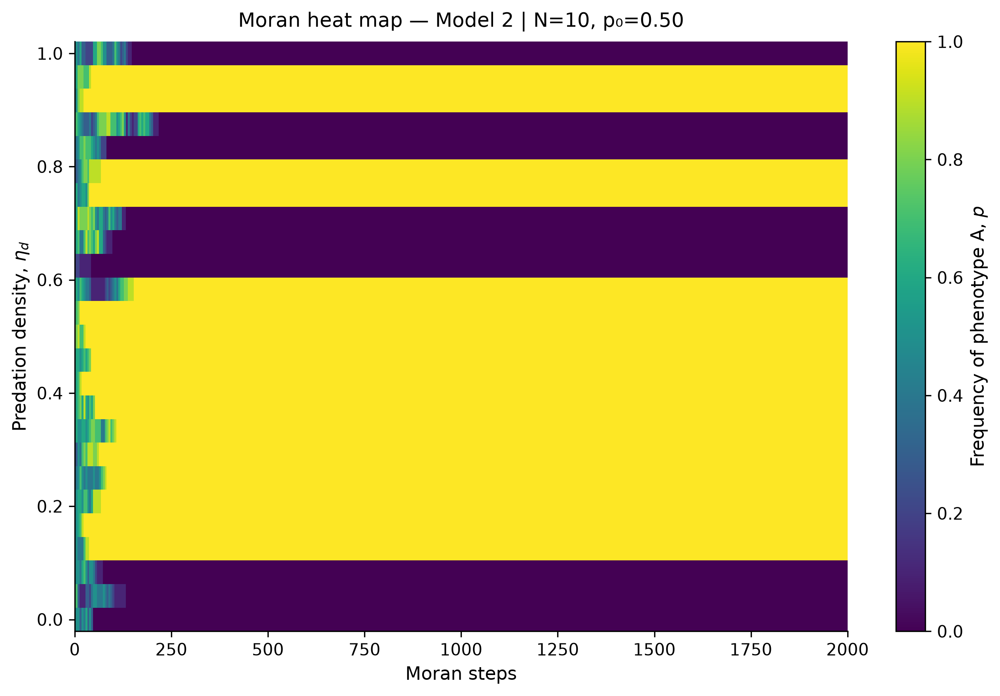

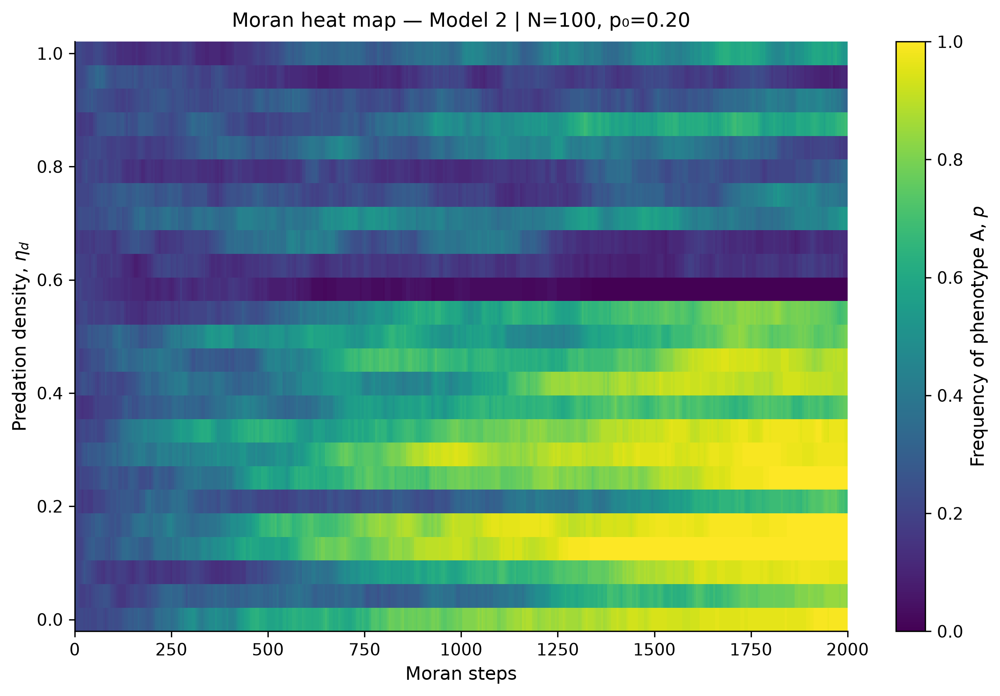

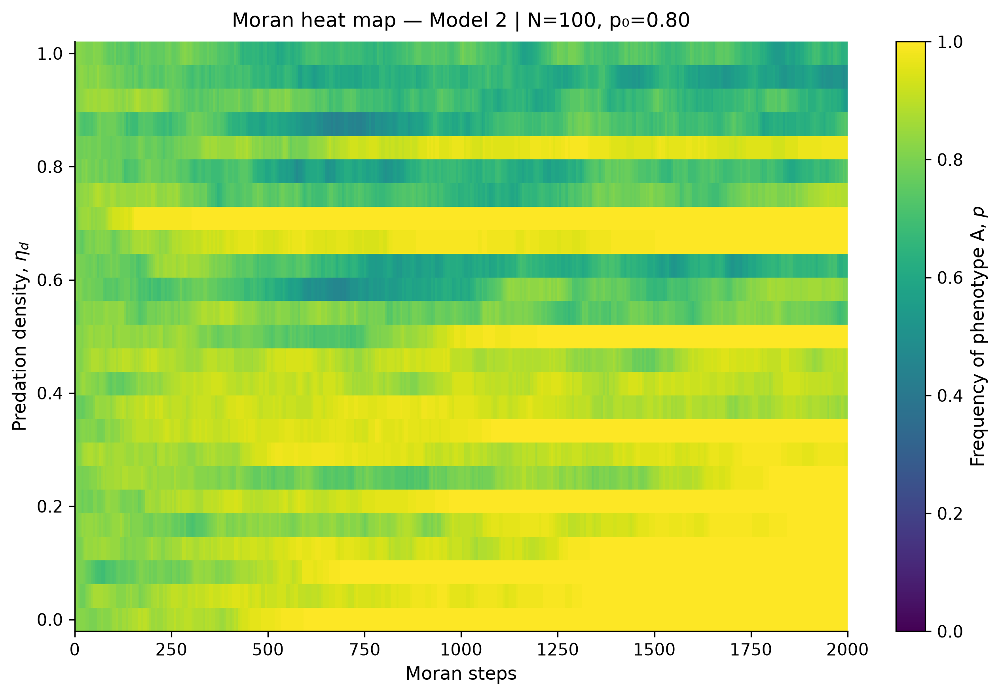

In [58]:
display(Image("Outputs/HeatPlot/Mod2_N10_p00.50_T2000_R1_E25.png"))
display(Image("Outputs/HeatPlot/Mod2_N100_p00.20_T2000_R1_E25.png"))
display(Image("Outputs/HeatPlot/Mod2_N100_p00.80_T2000_R1_E25.png"))

7. Fitness Landscape

In [59]:
graficarFitness(
    2, (WAA_2, WAB_2, WBA_2, WBB_2),
    p, eta_d
)

In [60]:
landscapes2 = {}

for n in N:
    f = lambda p0, eta: drift(
        p0, eta,
        N=n, steps=T, R=steps,
        WAA=WAA_2, WAB=WAB_2, WBA=WBA_2, WBB=WBB_2
    )

    X, Y, Z = DeltaW(p, eta_d, f, 0)
    Zs = suavizarDrift(Z)

    # Preserve absorbing boundaries without mutation
    Zs[:, 0], Zs[:, -1] = Z[:, 0], Z[:, -1]
    landscapes2[n] = (X, Y, Z, Zs)

    for filtro, valores in [('Raw', Z), ('Gaussian', Zs)]:
        ia.plotFL(
            tamanio=(950, 650),
            legendname='Mean drift per Moran step',
            tittle=f'{filtro} drift — Model 2 | N={n}',
            xlabel='Initial frequency, p₀',
            ylabel='Predation density, ηd',
            save_name=f'Model2_N{n}_{filtro}',
            X=X, Y=Y, Z=valores
        )

    print(f"N={n} | Raw + Gaussian saved")

print(f"Total: {2*len(N)} HTML files.")

N=10 | Raw + Gaussian saved
N=100 | Raw + Gaussian saved
Total: 4 HTML files.


In [61]:
n, filtro  = 10, 'Raw' 

X, Y, Z, Zs = landscapes2[n]

fig = ia.plotFL(
    tamanio=(950, 650),
    legendname='Mean drift per Moran step',
    tittle=f'{filtro} drift — Model 2 | N={n}',
    xlabel='Initial frequency, p₀',
    ylabel='Predation density, ηd',
    save_name=None,
    X=X, Y=Y, Z=Z if filtro == 'Raw' else Zs
)

fig.show(renderer='notebook')


In [62]:

n, filtro  = 10, 'Gaussian' 

X, Y, Z, Zs = landscapes2[n]

fig = ia.plotFL(
    tamanio=(950, 650),
    legendname='Mean drift per Moran step',
    tittle=f'{filtro} drift — Model 2 | N={n}',
    xlabel='Initial frequency, p₀',
    ylabel='Predation density, ηd',
    save_name=None,
    X=X, Y=Y, Z=Z if filtro == 'Raw' else Zs
)

fig.show(renderer='notebook')


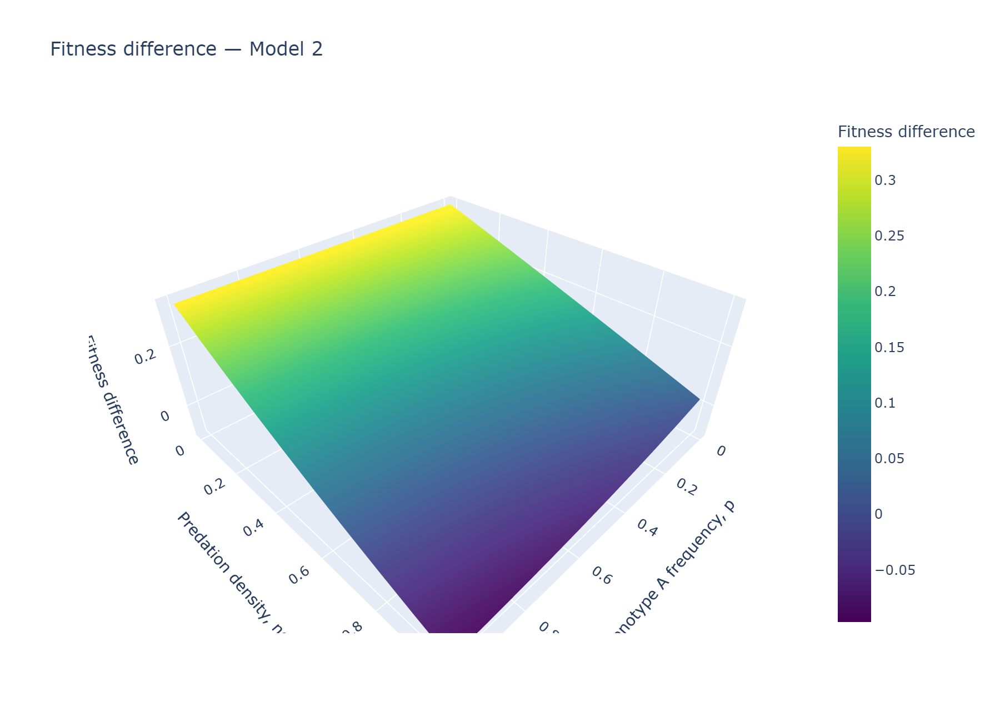

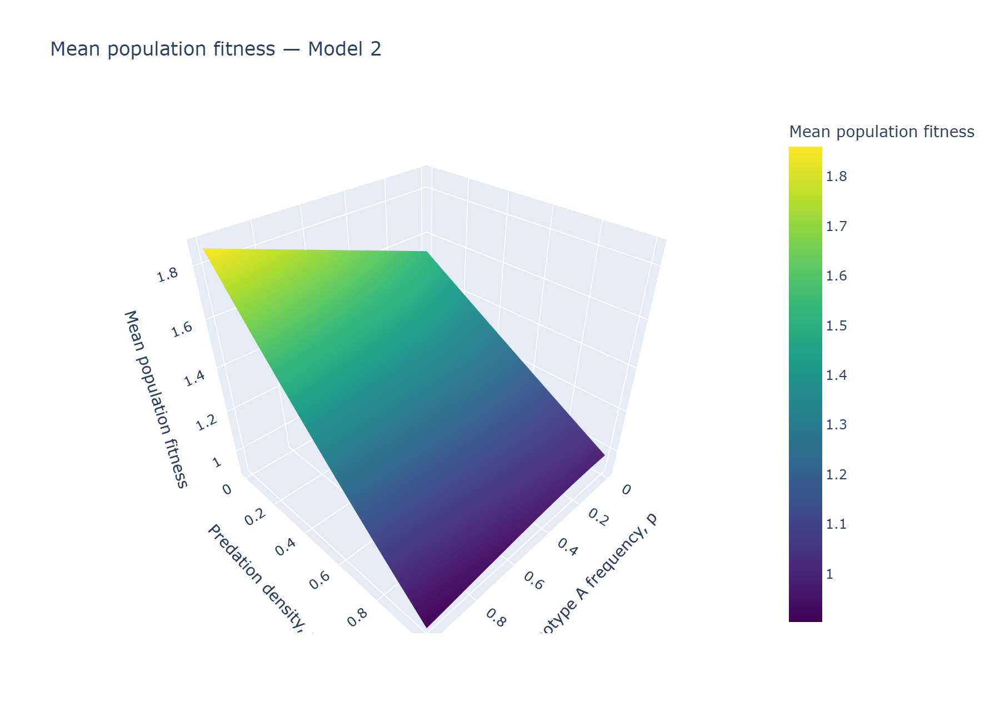

In [63]:

carpeta = Path('Outputs/FitnessLandscape')

for tipo in ['difFit', 'meanFit']:
    archivo = carpeta / f'mod2_{tipo}.png'

    if archivo.exists():
        display(IPyImage(filename=str(archivo)))
    else:
        print(f'File not found: {archivo}')


---
### Modelo 3: Pagos dependientes de la frecuencia y parámetros no lineales. 

1. Definición de las entradas para la matriz.


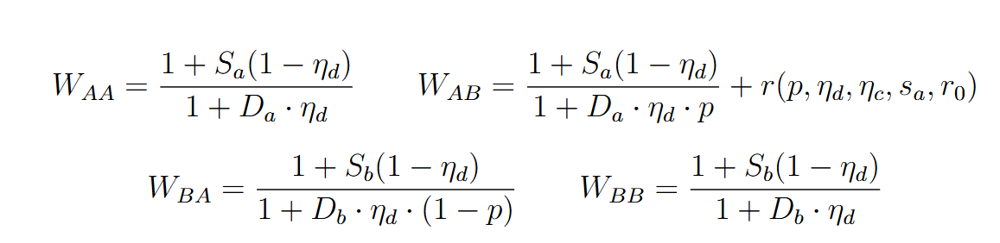

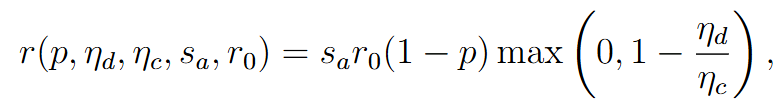

In [64]:
display(Image(filename='Inputs/NoLinearParameters.png'))
display(Image(filename='Inputs/r.png'))

In [65]:
def r_saturacion(p, eta_d, eta_c, r0, sa=s_a):
    return sa*r0*(1-p)*max(0, 1-eta_d/eta_c)

def WAA_3(p, eta_d, eta_c, r0, sa=s_a, da=d_a):
    return (
        (1+sa*(1-eta_d))/(1+eta_d*da)
        + r_saturacion(p, eta_d, eta_c, r0, sa=sa)
    )


2. Análisis de estabilidad, barrido de parámetros y gráfica que analiza régimenes.

In [66]:
# Find parameters for different stability regimes — Model 3
ejemplos3 = findParametersNoLineal(
    WAA_3, WAB_2, WBA_2, WBB_2,
    rangos={'eta_d': (0, 1)},
    eta_c=eta_c,
    r0=r0_fijo3
)

display(ejemplos3[
    ['target', 'found', 'eta_d', 'r0', 'eta_c', 'regime', 'p_star']
])


,target,found,eta_d,r0,eta_c,regime,p_star
0,A dominates B,True,0.466308,0.25,0.776,A dominates B,NaN
1,B dominates A,False,1.000000,0.25,0.776,Stable coexistence,0.116751
2,Stable coexistence,True,0.786161,0.25,0.776,Stable coexistence,0.659754
3,Bistability,False,0.874360,0.25,0.776,Stable coexistence,0.379104
4,Neutrality,False,0.846344,0.25,0.776,Stable coexistence,0.454435
5,Multiple equilibria,False,0.752512,0.25,0.776,Stable coexistence,0.840573


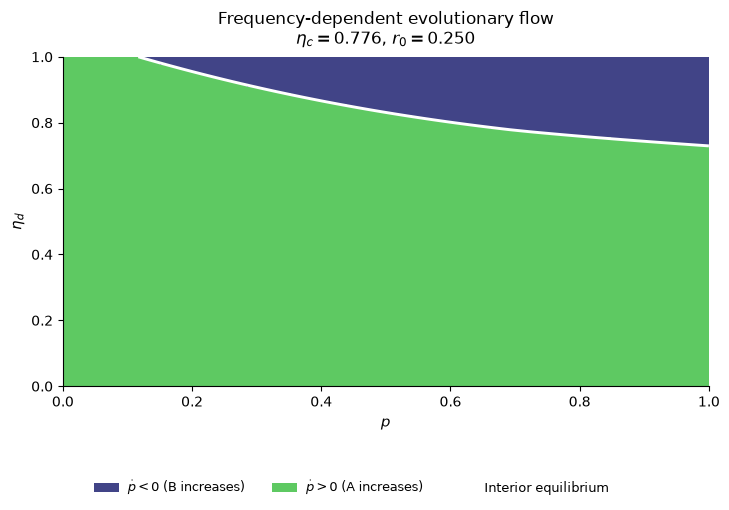

In [67]:

tabla3 = barridoParametrosNoLineal(
    WAA_3, WAB_2, WBA_2, WBB_2,
    barridos={'eta_d': np.linspace(0, 1, 50)},
    eta_c=eta_c,
    r0=r0_fijo3,
    archivo='Outputs/EqReplicador/StabilityModelo3.csv'
)


fig, ax = ia.mapaFlujoNoLineal(
    WAA_3, WAB_2, WBA_2, WBB_2,
    eta_d=np.linspace(0, 1, 150),
    p=np.linspace(0, 1, 150),
    eta_c=eta_c,
    r0=r0_fijo3,
    nombre='StabilityModelo3'
)


3. Gráfica de replicador con parámetros elegidos

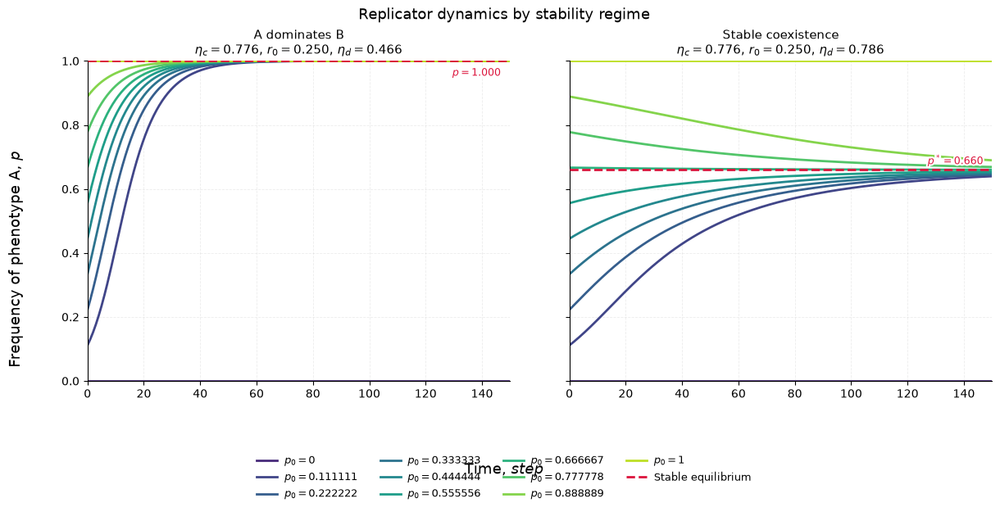

In [68]:
eta_c, r0= 0.776, 0.25

fig, axes = ia.plotRegimenesReplicador(
    ejemplos3, eqReplicador,
    WAA_3, WAB_2, WBA_2, WBB_2,
    pInicial=p,
    parametros=('eta_d',),
    fijos={'eta_c': eta_c, 'r0': r0},
    tFinal=150,
    nombre='regimenes_replicador_modelo3'
)


4. Creación de Matriz de Markov

In [69]:
eta_c = 0.776
r0_vals = np.linspace(0, 0.25, 5)

dicc3, convergencias3 = {}, {}

for n in N:
    inicio = datetime.now()
    x0 = np.zeros(n + 1)
    x0[n // 2] = 1
    combinaciones = 0

    for eta in eta_d:
        for r_val in r0_vals:
            M3 = matriz_transicion(
                n, WAA=WAA_3, WAB=WAB_2, WBA=WBA_2, WBB=WBB_2,
                eta_d=float(eta), eta_c=eta_c, r0=float(r_val)
            )
            tconv, _ = tiempo_convergencia(M3, x0, tol=1e-6)
            resultados = analizar_ecuacion_maestra(M3, x0, n_pasos=15000)

            clave = (n, round(float(eta), 5), round(float(r_val), 5))
            dicc3[clave] = resultados
            convergencias3[clave] = tconv
            combinaciones += 1

    duracion = (datetime.now() - inicio).total_seconds()
    print(f"N={n} | {combinaciones} combinations | Execution: {duracion:.2f} s")


N=10 | 50 combinations | Execution: 1.24 s
N=100 | 50 combinations | Execution: 9.60 s


5. Grafica de ecuación Maestra basada en la matriz de transiciones

In [70]:
carpeta = Path('Outputs/MasterEquation')
carpeta.mkdir(parents=True, exist_ok=True)

for (n, eta, r_val), resultados in dicc3.items():
    fig, ax = ia.graficarEcuacionMaestra(
        resultados, N=n, eta_d=eta, eta_c=eta_c, r0=r_val,
        guardar=f"Outputs/MasterEquation/Mod3_N{n}_eta{eta:.3f}_r0{r_val:.3f}.png",
        mostrar=False
    )
    plt.close(fig)

print(f"{len(dicc3)} plots saved in {carpeta}/")


100 plots saved in Outputs\MasterEquation/


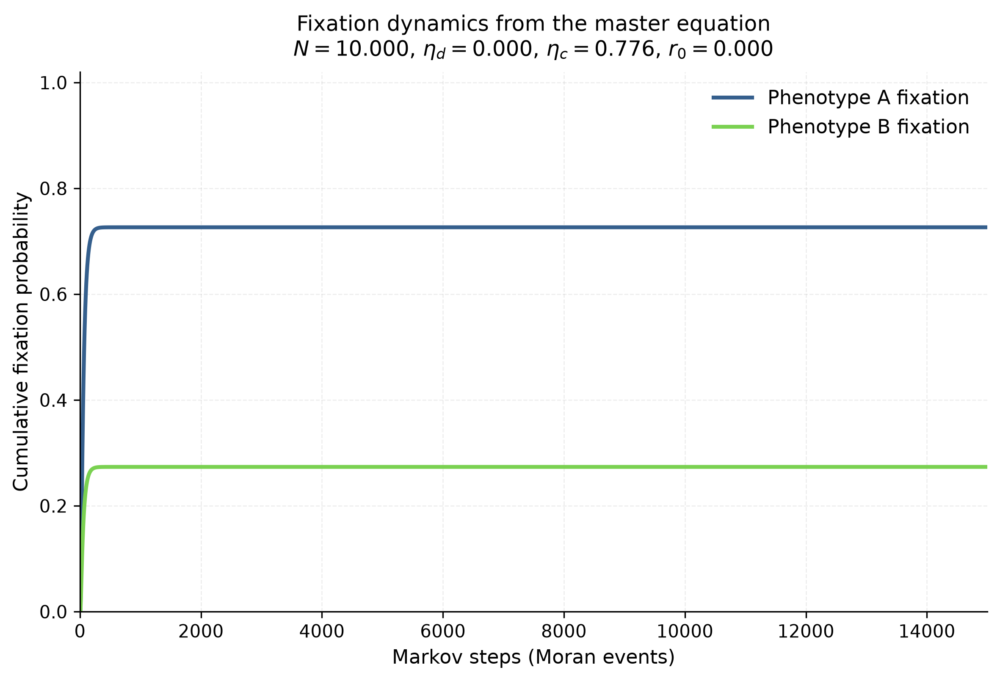

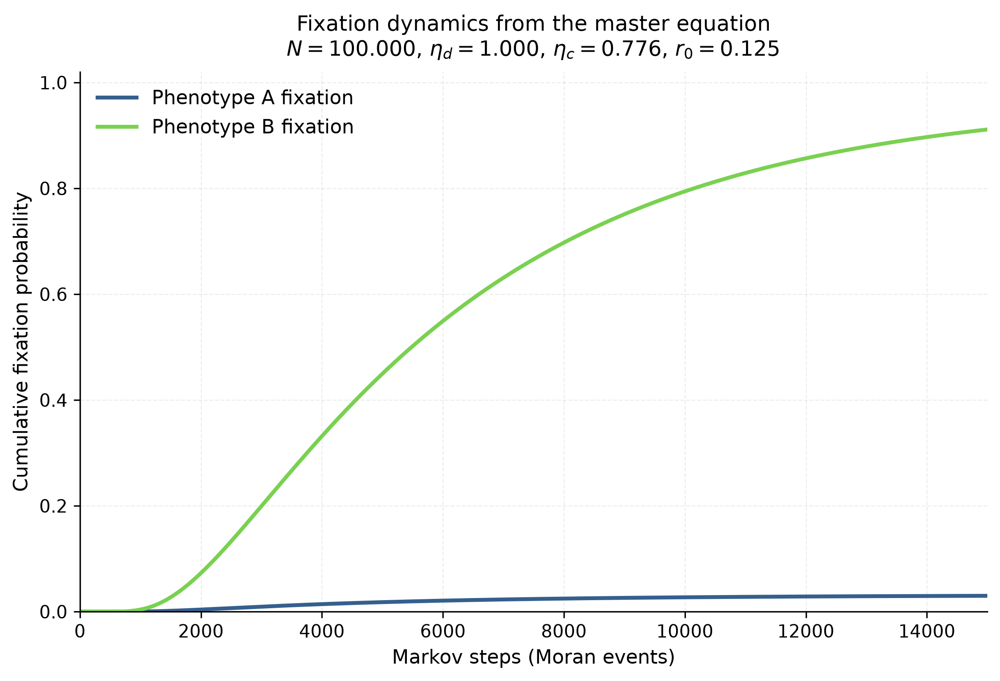

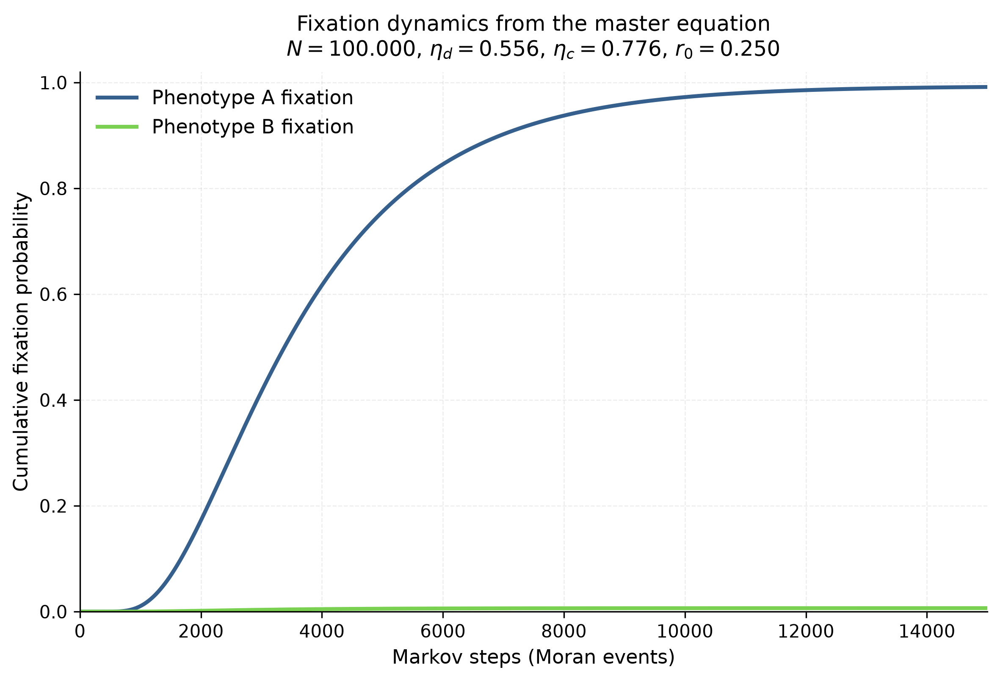

In [71]:

from IPython.display import Image as IPyImage, display

display(IPyImage(filename="Outputs/MasterEquation/Mod3_N10_eta0.000_r00.000.png"))
display(IPyImage(filename="Outputs/MasterEquation/Mod3_N100_eta1.000_r00.125.png"))
display(IPyImage(filename="Outputs/MasterEquation/Mod3_N100_eta0.556_r00.250.png"))


6. Grafica del Proceso de Moran

In [72]:
carpeta = Path('Outputs/MoranProcess')
carpeta.mkdir(parents=True, exist_ok=True)

eta_c = 0.776
r0     = np.linspace(0, 0.25, 5)

for n in N:
    for eta in eta_d:
        for r_val in r0:
            par = {'eta_d': float(eta), 'eta_c': eta_c, 'r0': float(r_val)}
            res = classificationNoLineal(WAA_3, WAB_2, WBA_2, WBB_2, **par)

            fig, ax = ia.plot(
                tamanio=(9, 6), p=p,
                legendname='Initial frequency',
                tittle=f"{res['regime']} | N={n}, ηd={eta:.3f}, r₀={r_val:.3f}, ηc={eta_c:.3f}",
                xlabel='Moran steps',
                ylabel=r'Frequency of phenotype A, $p$',
                save_name=None, process_func=MPFitDinamico,
                N=n, T=T, g=0, poisson=False, seed=42,
                WAA=WAA_3, WAB=WAB_2, WBA=WBA_2, WBB=WBB_2,
                **par, mostrar=False
            )

            # Deterministic reference equilibria
            eq = list(res['equilibria'])
            eq += [{'p': q, 'stability': res[key]}
                   for q, key in [(0, 'p0'), (1, 'p1')]]

            for e in eq:
                if e['stability'] not in ('Stable', 'Unstable'): continue
                stable = e['stability'] == 'Stable'
                color = 'crimson' if stable else '#404040'
                ax.axhline(e['p'], color=color, ls='--' if stable else ':', lw=1.5)
                ax.annotate(fr"$p^*={e['p']:.3f}$",
                            (.98, e['p']), xycoords=('axes fraction', 'data'),
                            xytext=(-3, 6 if e['p'] < .95 else -12),
                            textcoords='offset points', ha='right', color=color)

            archivo = f'Mod3_N{n}_eta{eta:.3f}_r0{r_val:.3f}_etac{eta_c:.3f}.png'
            fig.savefig(carpeta / archivo, dpi=300, bbox_inches='tight')
            plt.close(fig)

    print(f"N={n}: {len(eta_d)*len(r0_vals)} plots saved.")

print(f"Total: {len(N)*len(eta_d)*len(r0_vals)} plots in {carpeta}/")


N=10: 50 plots saved.
N=100: 50 plots saved.
Total: 100 plots in Outputs\MoranProcess/


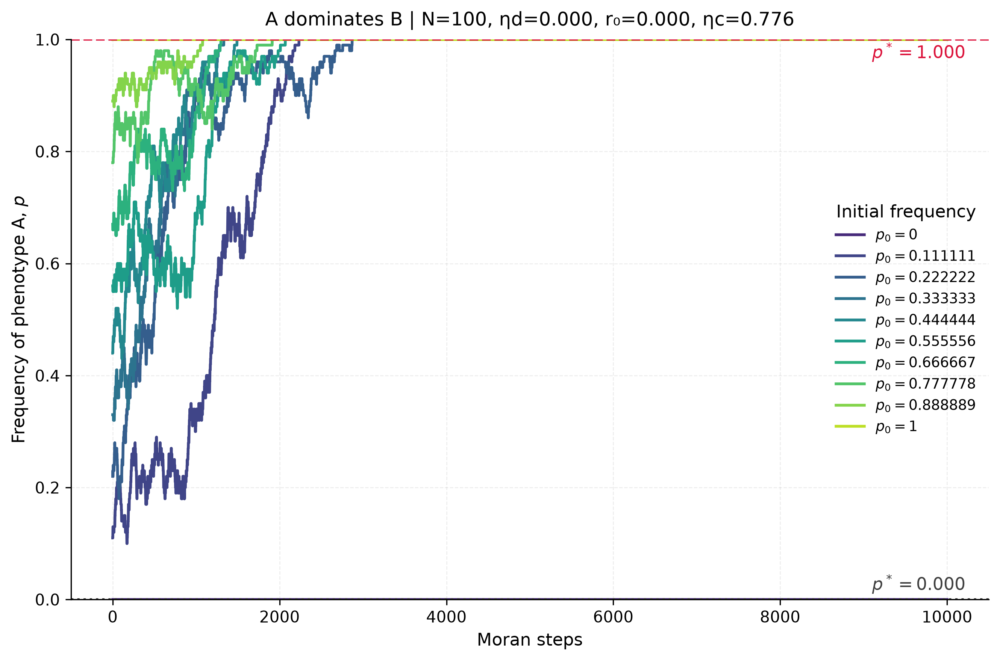

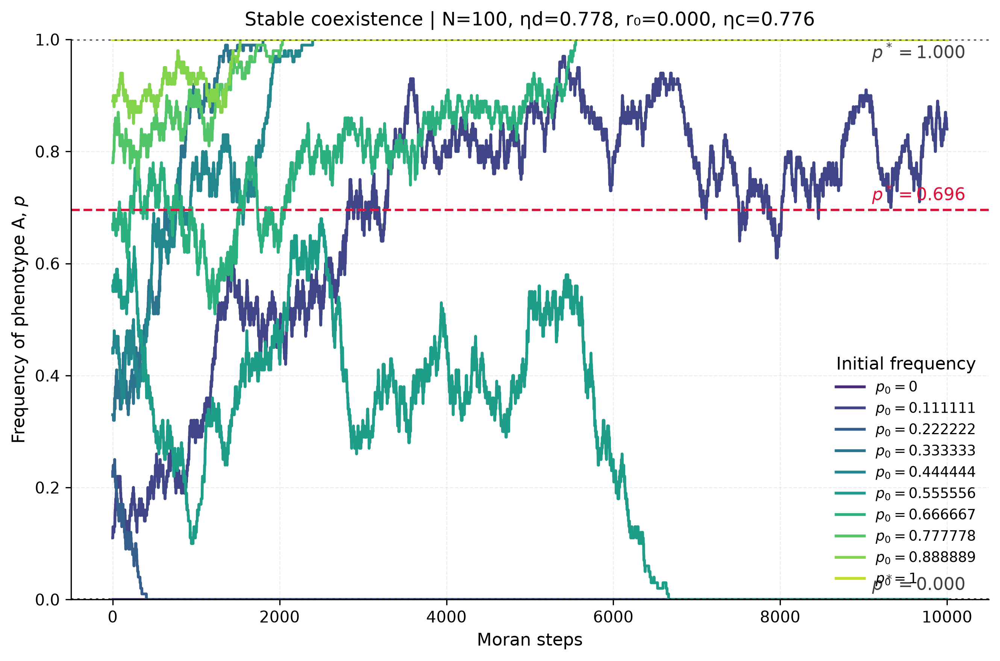

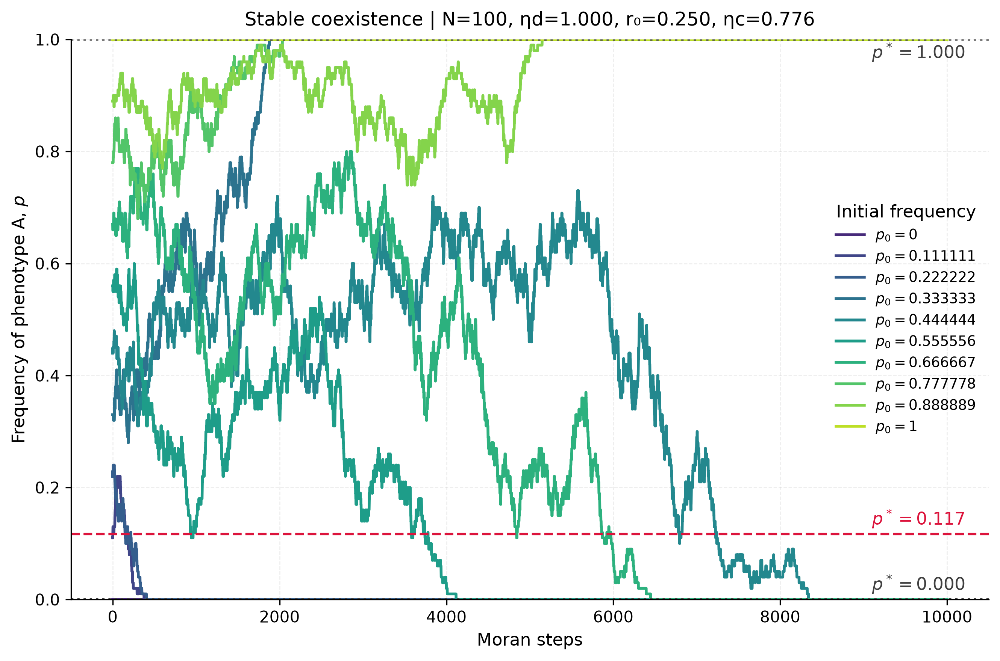

In [73]:
display(Image("Outputs/MoranProcess/Mod3_N100_eta0.000_r00.000_etac0.776.png"))
display(Image("Outputs/MoranProcess/Mod3_N100_eta0.778_r00.000_etac0.776.png"))
display(Image("Outputs/MoranProcess/Mod3_N100_eta1.000_r00.250_etac0.776.png"))

6.5. Mapa de Calor.

In [74]:
barridoHeat(
    3, (WAA_3, WAB_2, WBA_2, WBB_2),
    Ns=N_heat, p0s=p0_heat, etas=eta_heat,
    r0s=r0_heat, eta_c=0.776,
    T_heat=T_heat, R_heat=R_heat, salto=salto_heat
)


Model 3: 12 heat maps saved in Outputs/HeatPlot/


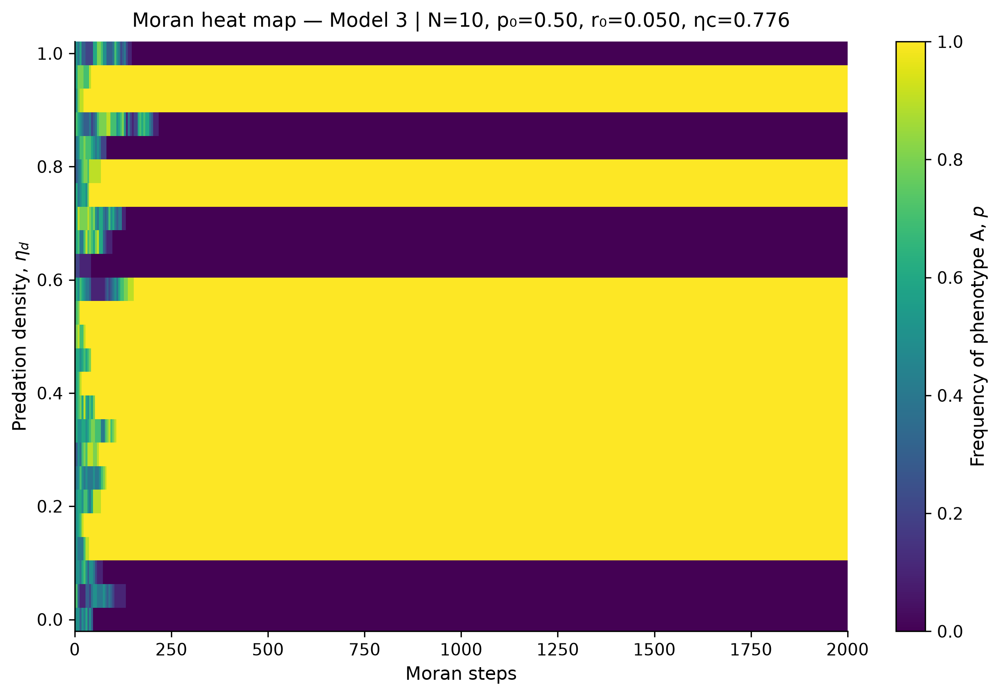

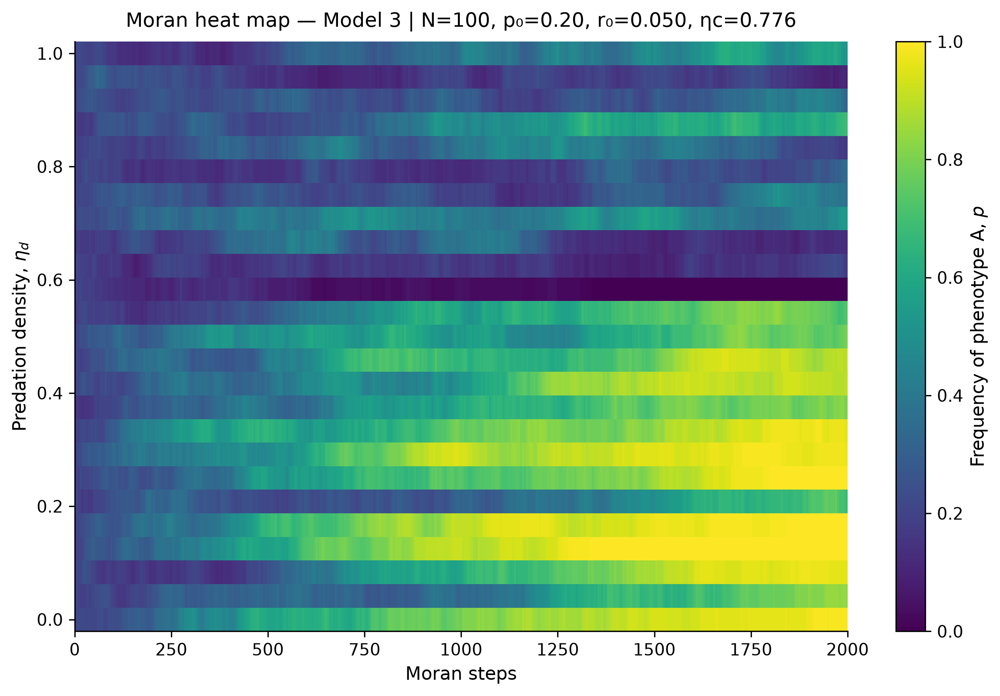

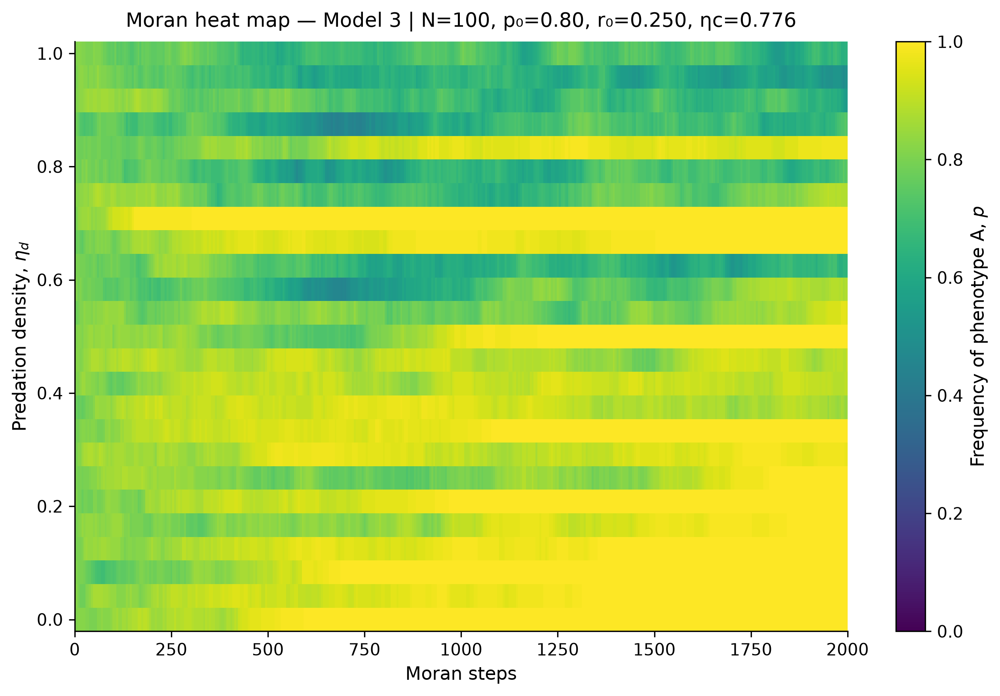

In [75]:
display(Image("Outputs/HeatPlot/Mod3_N10_p00.50_r00.0500_etac0.776_T2000_R1_E25.png"))
display(Image("Outputs/HeatPlot/Mod3_N100_p00.20_r00.0500_etac0.776_T2000_R1_E25.png"))
display(Image("Outputs/HeatPlot/Mod3_N100_p00.80_r00.2500_etac0.776_T2000_R1_E25.png"))

7. Fitness Landscape

In [76]:
eta_c = 0.776
r0_vals = np.linspace(0, 0.25, 5)

for r_val in r0_vals:
    graficarFitness(
        3, (WAA_3, WAB_2, WBA_2, WBB_2),
        p, eta_d, eta_c=eta_c, r0=float(r_val)
    )

In [77]:
landscapes3 = {}

for n in N:
    for r_val in r0_vals:
        f = lambda p0, eta: drift(
            p0, eta, N=n, steps=T, R=steps,
            WAA=WAA_3, WAB=WAB_2, WBA=WBA_2, WBB=WBB_2,
            eta_c=eta_c, r0=float(r_val)
        )

        X, Y, Z = DeltaW(p, eta_d, f, 0)
        Zs = suavizarDrift(Z)

        # Preserve absorbing boundaries without mutation
        Zs[:, 0], Zs[:, -1] = Z[:, 0], Z[:, -1]
        landscapes3[(n, round(float(r_val), 5))] = (X, Y, Z, Zs)

        for filtro, valores in [('Raw', Z), ('Gaussian', Zs)]:
            ia.plotFL(
                tamanio=(950, 650),
                legendname='Mean drift per Moran step',
                tittle=f'{filtro} drift — Model 3 | N={n}, r₀={r_val:.4f}, ηc={eta_c:.3f}',
                xlabel='Initial frequency, p₀',
                ylabel='Predation density, ηd',
                save_name=f'Model3_N{n}_r0{r_val:.4f}_etac{eta_c:.3f}_{filtro}',
                X=X, Y=Y, Z=valores
            )

        print(f"N={n}, r0={r_val:.4f} | Raw + Gaussian saved")

print(f"Total: {2*len(N)*len(r0_vals)} HTML files.")


N=10, r0=0.0000 | Raw + Gaussian saved
N=10, r0=0.0625 | Raw + Gaussian saved
N=10, r0=0.1250 | Raw + Gaussian saved
N=10, r0=0.1875 | Raw + Gaussian saved
N=10, r0=0.2500 | Raw + Gaussian saved
N=100, r0=0.0000 | Raw + Gaussian saved
N=100, r0=0.0625 | Raw + Gaussian saved
N=100, r0=0.1250 | Raw + Gaussian saved
N=100, r0=0.1875 | Raw + Gaussian saved
N=100, r0=0.2500 | Raw + Gaussian saved
Total: 20 HTML files.


In [78]:

n = 10
r_val = 0.0625
filtro = 'Raw'  # 'Raw' or 'Gaussian'

X, Y, Z, Zs = landscapes3[(n, round(r_val, 5))]

fig = ia.plotFL(
    tamanio=(950, 650),
    legendname='Mean drift per Moran step',
    tittle=f'{filtro} drift — Model 3 | N={n}, r₀={r_val:.4f}, ηc={eta_c:.3f}',
    xlabel='Initial frequency, p₀',
    ylabel='Predation density, ηd',
    save_name=None,
    X=X, Y=Y, Z=Z if filtro == 'Raw' else Zs
)

fig.show(renderer='notebook')


In [79]:

n = 10
r_val = 0.0625
filtro = 'Gaussian'  # 'Raw' or 'Gaussian'

X, Y, Z, Zs = landscapes3[(n, round(r_val, 5))]

fig = ia.plotFL(
    tamanio=(950, 650),
    legendname='Mean drift per Moran step',
    tittle=f'{filtro} drift — Model 3 | N={n}, r₀={r_val:.4f}, ηc={eta_c:.3f}',
    xlabel='Initial frequency, p₀',
    ylabel='Predation density, ηd',
    save_name=None,
    X=X, Y=Y, Z=Z if filtro == 'Raw' else Zs
)

fig.show(renderer='notebook')
